# Knowing when to refer: uncertainty-aware soft-computing triage for dermoscopic skin cancer

Binary (benign vs malignant) classification on HAM10000 with a three-way triage output: **benign**, **malignant** or **refer**.


## 1. Setup and configuration

In [1]:
!pip install timm grad-cam --quiet

import os, glob, json, math, random, warnings, copy
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import timm
import torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from sklearn.metrics import roc_auc_score, accuracy_score, confusion_matrix, roc_curve, auc
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
warnings.filterwarnings("ignore")

SEED=42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()

plt.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 300, "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25,
})

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

HAM_CSV      = "/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_metadata.csv"
HAM_IMG_DIRS = [
    "/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1/",
    "/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_2/",
]
SAVE_DIR="/kaggle/working/"; FIG_DIR="/kaggle/working/figures/"; SPLITS_DIR="/kaggle/working/splits/"
for d in [FIG_DIR,SPLITS_DIR]: os.makedirs(d,exist_ok=True)

BATCH_SIZE=64; NUM_EPOCHS=30; PATIENCE=7; IMG_SIZE=224
HAM_MALIGNANT={"mel","bcc","akiec"}
USE_TTA=True
EMA_DECAY=0.998

MODELS={
    "convnext_tiny":"convnext_tiny.fb_in22k_ft_in1k",
    "maxvit_tiny":"maxvit_tiny_tf_224.in1k",
    "swin_tiny":"swin_tiny_patch4_window7_224",
}

HAM_LOOKUP={}
for d in HAM_IMG_DIRS:
    for fp in glob.glob(d+"*.jpg"):
        HAM_LOOKUP[os.path.basename(fp).replace(".jpg","")]=fp
print(f"HAM images indexed: {len(HAM_LOOKUP):,}")

class SkinModel(nn.Module):
    def __init__(self, backbone_name, dropout=0.5):
        super().__init__()
        self.backbone = timm.create_model(backbone_name, pretrained=True, num_classes=0)
        self.head = nn.Sequential(nn.Dropout(dropout),
                                  nn.Linear(self.backbone.num_features, 2))
    def forward(self,x): return self.head(self.backbone(x))

class FocalLoss(nn.Module):
    def __init__(self, alpha=0.75, gamma=2.0):
        super().__init__(); self.alpha,self.gamma=alpha,gamma
    def forward(self, logits, target):
        ce=F.cross_entropy(logits,target,reduction="none")
        pt=torch.exp(-ce)
        w=torch.where(target==1,self.alpha,1-self.alpha)
        return (w*(1-pt)**self.gamma*ce).mean()

class EMA:
    """Exponential moving average of model weights; used for evaluation."""
    def __init__(self, model, decay=EMA_DECAY):
        self.decay=decay
        self.shadow={k:v.clone().detach() for k,v in model.state_dict().items()}
    def update(self, model):
        with torch.no_grad():
            for k,v in model.state_dict().items():
                if v.dtype.is_floating_point:
                    self.shadow[k].mul_(self.decay).add_(v.detach(),alpha=1-self.decay)
                else:
                    self.shadow[k]=v.clone()
    def copy_to(self, model):
        model.load_state_dict(self.shadow)

print("Setup complete.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 1.2 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Device: cuda
HAM images indexed: 10,015
Setup complete.


## 2. Binary labels and lesion-level splits

In [2]:
set_seed()
ham=pd.read_csv(HAM_CSV)
ham["target"]=ham["dx"].apply(lambda x:1 if x in HAM_MALIGNANT else 0)
ham["image_name"]=ham["image_id"]
ham=ham[ham.image_id.isin(HAM_LOOKUP)].reset_index(drop=True)
print(f"Total images: {len(ham)} | malignant {ham.target.mean()*100:.1f}%")

linfo=ham.groupby("lesion_id")["target"].max().reset_index().rename(columns={"target":"has_pos"})
tr,tmp=train_test_split(linfo,test_size=0.30,stratify=linfo.has_pos,random_state=SEED)
va,te =train_test_split(tmp,test_size=0.50,stratify=tmp.has_pos,random_state=SEED)
ham_tr=ham[ham.lesion_id.isin(tr.lesion_id)].reset_index(drop=True)
ham_va=ham[ham.lesion_id.isin(va.lesion_id)].reset_index(drop=True)
ham_te=ham[ham.lesion_id.isin(te.lesion_id)].reset_index(drop=True)
assert not (set(ham_tr.lesion_id)&set(ham_te.lesion_id)), "LEAK"
assert not (set(ham_tr.lesion_id)&set(ham_va.lesion_id)), "LEAK"
for nm,df in [("train",ham_tr),("val",ham_va),("test",ham_te)]:
    df.to_csv(SPLITS_DIR+f"ham_{nm}.csv",index=False)
    print(f"  {nm:<6} {len(df):>5} | malignant {df.target.mean()*100:.1f}%")
print("Splits saved, zero leakage verified.")

Total images: 10015 | malignant 19.5%
  train   7010 | malignant 19.5%
  val     1500 | malignant 19.8%
  test    1505 | malignant 19.1%
Splits saved, zero leakage verified.


## 3. Figure: class distribution

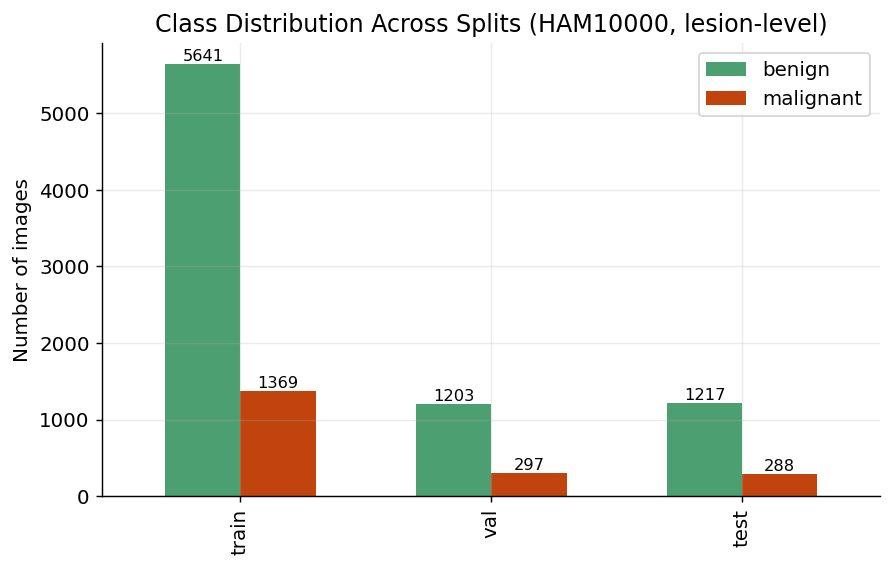

Saved figures/fig02_class_distribution.png


In [3]:
splits_summary = pd.DataFrame({
    "split": ["train","train","val","val","test","test"],
    "class": ["benign","malignant"]*3,
    "count": [
        (ham_tr.target==0).sum(), (ham_tr.target==1).sum(),
        (ham_va.target==0).sum(), (ham_va.target==1).sum(),
        (ham_te.target==0).sum(), (ham_te.target==1).sum(),
    ],
})
fig,ax=plt.subplots(figsize=(7,4.5))
pivot=splits_summary.pivot(index="split",columns="class",values="count").loc[["train","val","test"]]
pivot.plot(kind="bar",stacked=False,ax=ax,color=["#4C9F70","#C1440E"],width=0.6)
for c in ax.containers: ax.bar_label(c,fmt="%d",fontsize=9)
ax.set_title("Class Distribution Across Splits (HAM10000, lesion-level)")
ax.set_ylabel("Number of images"); ax.set_xlabel("")
ax.legend(title="")
fig.tight_layout()
fig.savefig(FIG_DIR+"fig02_class_distribution.png",bbox_inches="tight")
plt.show()
print("Saved figures/fig02_class_distribution.png")

## 4. Datasets and transforms

In [4]:
NORM=T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
class RandomRot90:
    """Random multiple of 90 degrees on a square image: exact, no borders."""
    def __call__(self, img):
        return img.rotate(90 * random.randint(0, 3))

train_tfm=T.Compose([T.Resize((IMG_SIZE,IMG_SIZE)),
                     T.RandomHorizontalFlip(),T.RandomVerticalFlip(),
                     RandomRot90(),
                     T.ColorJitter(0.1,0.1,0.1),
                     T.ToTensor(),NORM,
                     T.RandomErasing(p=0.25,scale=(0.02,0.1))])
eval_tfm =T.Compose([T.Resize((IMG_SIZE,IMG_SIZE)),T.ToTensor(),NORM])
viz_tfm  =T.Compose([T.Resize((IMG_SIZE,IMG_SIZE)),
                     T.RandomHorizontalFlip(),T.RandomVerticalFlip(),
                     RandomRot90(),
                     T.ColorJitter(0.1,0.1,0.1)])

class HAMds(Dataset):
    def __init__(self,csv,tfm):
        self.df=pd.read_csv(csv); self.t=tfm
    def __len__(self): return len(self.df)
    def __getitem__(self,i):
        r=self.df.iloc[i]
        img=Image.open(HAM_LOOKUP[r["image_name"]]).convert("RGB")
        return self.t(img), int(r["target"])

def make_loader(csv,tfm,shuffle,sampler=None,bs=BATCH_SIZE):
    ds=HAMds(csv,tfm)
    if sampler is not None:
        return DataLoader(ds,batch_size=bs,sampler=sampler,num_workers=2)
    return DataLoader(ds,batch_size=bs,shuffle=shuffle,num_workers=2)
print("Datasets ready.")

Datasets ready.


## 5. Figure: augmentation examples

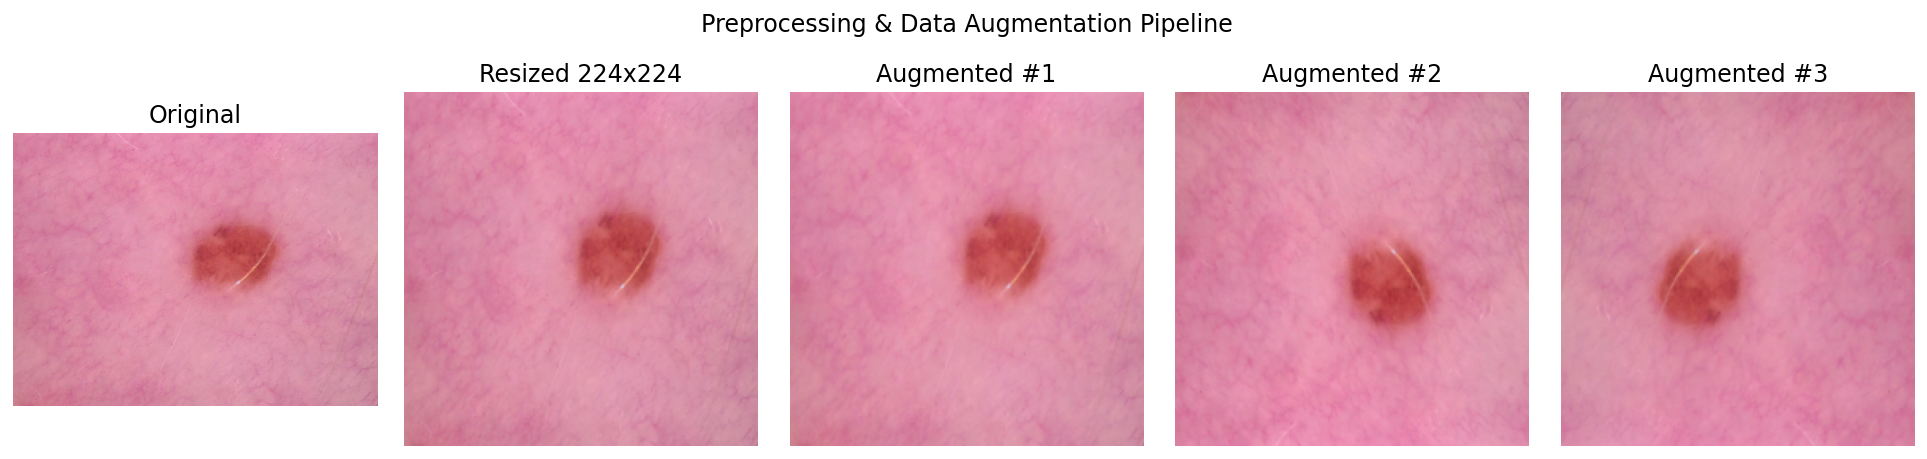

Saved figures/fig03_augmentation_examples.png


In [5]:
set_seed()
sample_row = ham_tr.sample(1,random_state=11).iloc[0]
orig_img = Image.open(HAM_LOOKUP[sample_row["image_name"]]).convert("RGB")

fig,axes=plt.subplots(1,5,figsize=(15,3.4))
axes[0].imshow(orig_img); axes[0].set_title("Original"); axes[0].axis("off")
axes[1].imshow(orig_img.resize((IMG_SIZE,IMG_SIZE))); axes[1].set_title(f"Resized {IMG_SIZE}x{IMG_SIZE}"); axes[1].axis("off")
for j in range(2,5):
    aug = viz_tfm(orig_img)
    axes[j].imshow(aug); axes[j].set_title(f"Augmented #{j-1}"); axes[j].axis("off")
fig.suptitle("Preprocessing & Data Augmentation Pipeline",y=1.03)
fig.tight_layout()
fig.savefig(FIG_DIR+"fig03_augmentation_examples.png",bbox_inches="tight")
plt.show()
print("Saved figures/fig03_augmentation_examples.png")

## 6. Training of the three backbones

In [6]:
from torch.utils.data import WeightedRandomSampler

def make_sampler(csv):
    df=pd.read_csv(csv); y=df.target.values
    n_pos=y.sum(); n_neg=len(y)-n_pos
    w_pos=min(n_neg/max(n_pos,1),15.0)
    weights=np.where(y==1,w_pos,1.0)
    return WeightedRandomSampler(weights,len(weights),replacement=True)

@torch.no_grad()
def eval_auc(model,loader):
    model.eval(); P,L=[],[]
    for x,y in loader:
        P.extend(torch.softmax(model(x.to(DEVICE)),1)[:,1].cpu().numpy()); L.extend(y.numpy())
    return roc_auc_score(L,P)

def train_one(mname,timm_name):
    set_seed()
    model=SkinModel(timm_name,0.5).to(DEVICE)
    ema=EMA(model)
    ema_model=SkinModel(timm_name,0.5).to(DEVICE)
    crit=FocalLoss(0.70,2.0)
    opt=torch.optim.AdamW([
        {"params":model.backbone.parameters(),"lr":1e-5},
        {"params":model.head.parameters(),"lr":1e-4}], weight_decay=5e-4)
    sched=torch.optim.lr_scheduler.CosineAnnealingLR(opt,T_max=NUM_EPOCHS)
    train_bs=32 if "maxvit" in mname else BATCH_SIZE
    tr_loader=make_loader(SPLITS_DIR+"ham_train.csv",train_tfm,False,sampler=make_sampler(SPLITS_DIR+"ham_train.csv"),bs=train_bs)
    va_loader=make_loader(SPLITS_DIR+"ham_val.csv",eval_tfm,False)
    best_auc,wait=0,0
    history={"train_loss":[],"val_auc":[]}
    print(f"\n=== Training {mname} (batch {train_bs}) ===")
    for ep in range(1,NUM_EPOCHS+1):
        model.train(); tot=0
        for x,y in tqdm(tr_loader,leave=False,desc=f"ep{ep}"):
            x,y=x.to(DEVICE),y.to(DEVICE)
            opt.zero_grad()
            loss=crit(model(x),y); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(),1.0)
            opt.step(); ema.update(model)
            tot+=loss.item()*x.size(0)
        sched.step()
        ema.copy_to(ema_model); ema_model.eval()
        vauc=eval_auc(ema_model,va_loader)
        train_loss=tot/len(tr_loader.dataset)
        history["train_loss"].append(train_loss); history["val_auc"].append(vauc)
        flag=""
        if vauc>best_auc or ep==1:
            best_auc=vauc; wait=0
            torch.save(ema_model.state_dict(),SAVE_DIR+f"model_{mname}.pth"); flag="  -> best (EMA) saved"
        else: wait+=1
        print(f"  ep{ep:2d} | train loss {train_loss:.4f} | val AUC (EMA) {vauc:.4f}{flag}")
        if wait>=PATIENCE: print("  early stop"); break
    del model, ema_model; torch.cuda.empty_cache()
    return best_auc, history

results, histories = {}, {}
for mname,timm_name in MODELS.items():
    results[mname],histories[mname]=train_one(mname,timm_name)
json.dump(histories, open(SAVE_DIR + "histories.json", "w"))
print("\nBest val AUCs (EMA):", {k:round(v,4) for k,v in results.items()})

model.safetensors:   0%|          | 0.00/114M [00:00<?, ?B/s]


=== Training convnext_tiny (batch 64) ===


  ep 1 | train loss 0.0903 | val AUC (EMA) 0.6125  -> best (EMA) saved


  ep 2 | train loss 0.0503 | val AUC (EMA) 0.7714  -> best (EMA) saved


  ep 3 | train loss 0.0442 | val AUC (EMA) 0.8454  -> best (EMA) saved


...

  ep20 | train loss 0.0134 | val AUC (EMA) 0.9317


  ep21 | train loss 0.0135 | val AUC (EMA) 0.9315


  ep22 | train loss 0.0127 | val AUC (EMA) 0.9316


  ep23 | train loss 0.0116 | val AUC (EMA) 0.9315


  ep24 | train loss 0.0131 | val AUC (EMA) 0.9318
  early stop

Best val AUCs (EMA): {'convnext_tiny': np.float64(0.9344), 'maxvit_tiny': np.float64(0.9333), 'swin_tiny': np.float64(0.9318)}


## 7. Figure: training curves

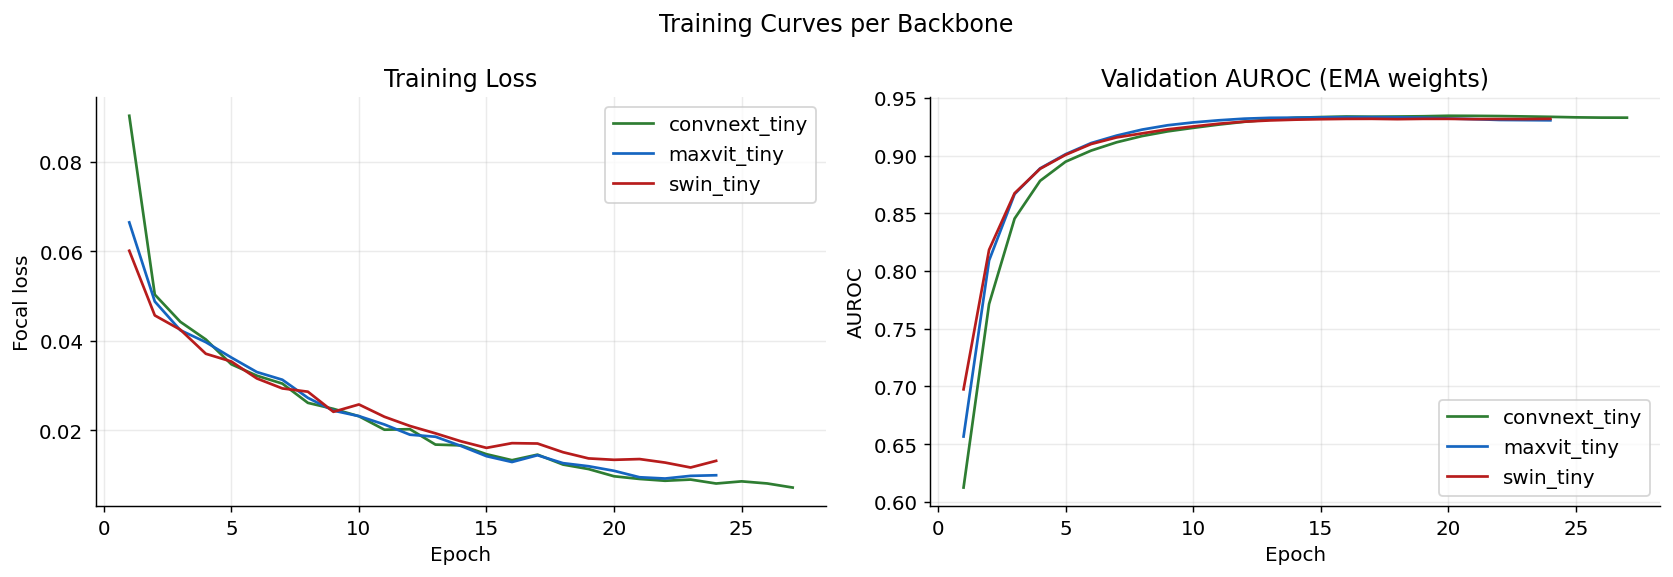

Saved figures/fig04_training_curves.png


In [7]:
colors={"convnext_tiny":"#2E7D32","maxvit_tiny":"#1565C0","swin_tiny":"#B71C1C"}
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
for mname,h in histories.items():
    axes[0].plot(range(1,len(h["train_loss"])+1),h["train_loss"],label=mname,color=colors.get(mname))
    axes[1].plot(range(1,len(h["val_auc"])+1),h["val_auc"],label=mname,color=colors.get(mname))
axes[0].set_title("Training Loss"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Focal loss"); axes[0].legend()
axes[1].set_title("Validation AUROC (EMA weights)"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("AUROC"); axes[1].legend()
fig.suptitle("Training Curves per Backbone")
fig.tight_layout()
fig.savefig(FIG_DIR+"fig04_training_curves.png",bbox_inches="tight")
plt.show()
print("Saved figures/fig04_training_curves.png")

## 8. Ensemble and validation-selected threshold

In [8]:
set_seed()
ENS_MODELS={}
for mname,timm_name in MODELS.items():
    m=SkinModel(timm_name,0.5).to(DEVICE)
    m.load_state_dict(torch.load(SAVE_DIR+f"model_{mname}.pth",map_location=DEVICE))
    m.eval(); ENS_MODELS[mname]=m

va_loader=make_loader(SPLITS_DIR+"ham_val.csv",eval_tfm,False,bs=BATCH_SIZE*2)
te_loader=make_loader(SPLITS_DIR+"ham_test.csv",eval_tfm,False,bs=BATCH_SIZE*2)

@torch.no_grad()
def per_model_probs(loader):
    allp={k:[] for k in ENS_MODELS}; L=[]
    for x,y in tqdm(loader,leave=False):
        x=x.to(DEVICE)
        views=[x]
        if USE_TTA:
            views += [torch.flip(x,dims=[3]), torch.flip(x,dims=[2]), torch.flip(x,dims=[2,3])]
        for k,m in ENS_MODELS.items():
            ps=[torch.softmax(m(v),1)[:,1] for v in views]
            allp[k].append(torch.stack(ps,0).mean(0).cpu().numpy())
        L.append(y.numpy())
    L=np.concatenate(L)
    return {k:np.concatenate(v) for k,v in allp.items()}, L

per_va,L_va=per_model_probs(va_loader)
per_te,L_te=per_model_probs(te_loader)
model_names=list(ENS_MODELS.keys())

def metrics_at(y,probs,t):
    p=(probs>=t).astype(int)
    tn,fp,fn,tp=confusion_matrix(y,p,labels=[0,1]).ravel()
    sens=tp/(tp+fn) if (tp+fn) else 0.0
    spec=tn/(tn+fp) if (tn+fp) else 0.0
    acc=(tp+tn)/len(y)
    return acc,sens,spec,(sens+spec)/2

def best_threshold_balanced(y,probs,min_sens=0.80):
    """Threshold maximising balanced accuracy with sensitivity >= min_sens."""
    best_t,best_bal,best_feasible=0.5,-1,-1
    for t in np.linspace(0.05,0.95,181):
        _,sens,spec,bal=metrics_at(y,probs,t)
        if sens>=min_sens and bal>best_feasible:
            best_feasible=bal; best_t=t
        if bal>best_bal:
            best_bal=bal
            if best_feasible<0: best_t=t
    return best_t

val_auc={k:roc_auc_score(L_va,per_va[k]) for k in model_names}
per_model_test={}
for k in model_names:
    t=best_threshold_balanced(L_va,per_va[k])
    per_model_test[k]=metrics_at(L_te,per_te[k],t)

X_va=np.stack([per_va[k] for k in model_names],1)
X_te=np.stack([per_te[k] for k in model_names],1)

candidates={}
meta=LogisticRegression(max_iter=1000,class_weight="balanced").fit(X_va,L_va)
candidates["stacking (meta-learner)"]=(meta.predict_proba(X_va)[:,1],meta.predict_proba(X_te)[:,1])
candidates["average (all 3)"]=(X_va.mean(1),X_te.mean(1))
w=np.array([val_auc[k] for k in model_names]); w=w/w.sum()
candidates["AUROC-weighted avg"]=(X_va@w,X_te@w)
top2=sorted(model_names,key=lambda k:val_auc[k],reverse=True)[:2]
i0,i1=model_names.index(top2[0]),model_names.index(top2[1])
candidates[f"2-model avg ({top2[0]}+{top2[1]})"]=((X_va[:,i0]+X_va[:,i1])/2,(X_te[:,i0]+X_te[:,i1])/2)

print(f"{'Combiner':<34}{'val bal-acc':>12}{'thr':>7}")
best=None
for name,(vp,tp) in candidates.items():
    t=best_threshold_balanced(L_va,vp)
    _,_,_,vbal=metrics_at(L_va,vp,t)
    print(f"  {name:<32}{vbal*100:>11.2f}%{t:>7.3f}")
    if best is None or vbal>best[1]: best=(name,vbal,t,vp,tp)

ens_kind,_,best_thr,ens_va,ens_te=best
combiner=("stacking" if ens_kind.startswith("stacking")
          else "average" if ens_kind.startswith("average")
          else "weighted" if ens_kind.startswith("AUROC") else "top2")
ens_kind=ens_kind+" + TTA"
ENS_LABEL={"stacking":"LR stacking","average":"equal weight","weighted":"AUROC-weighted","top2":"top-2 mean"}[combiner]

aucs={k:roc_auc_score(L_te,per_te[k]) for k in model_names}
ens_auc=roc_auc_score(L_te,ens_te)
acc,sens,spec,bal=metrics_at(L_te,ens_te,best_thr)
preds=(ens_te>=best_thr).astype(int)

print("\n"+"="*66)
print("ENSEMBLE ON HAM10000 TEST — tuned for balanced accuracy")
print("="*66)
print(f"{'Model':<22}{'AUROC':>9}{'Acc':>8}{'Sens':>8}{'Spec':>8}{'Bal':>8}")
for k in model_names:
    a,se,sp,ba=per_model_test[k]
    print(f"  {k:<20}{aucs[k]:>9.4f}{a*100:>7.1f}%{se*100:>7.1f}%{sp*100:>7.1f}%{ba*100:>7.1f}%")
print(f"  {'ENSEMBLE':<20}{ens_auc:>9.4f}{acc*100:>7.1f}%{sens*100:>7.1f}%{spec*100:>7.1f}%{bal*100:>7.1f}%")
print("-"*66)
print(f"Combiner        : {ens_kind}")
print(f"Threshold (val) : {best_thr:.3f}")
print(f"Accuracy        : {acc*100:.2f}%")
print(f"Sensitivity     : {sens*100:.2f}%")
print(f"Specificity     : {spec*100:.2f}%")
print(f"Balanced acc    : {bal*100:.2f}%")
best_single=max(model_names,key=lambda k:per_model_test[k][3])
gap=(bal-per_model_test[best_single][3])*100
print(f"Best single model ({best_single}) bal acc {per_model_test[best_single][3]*100:.2f}% "
      f"-> ensemble gap {gap:+.2f} pts (test significance with DeLong in section 19)")
if "stacking" in ens_kind:
    print("Meta-learner weights:", {k: round(float(w), 3) for k, w in zip(model_names, meta.coef_[0])})

meta_coef={k:round(float(c),4) for k,c in zip(model_names,meta.coef_[0])} if combiner=="stacking" else None
deploy_cfg={"threshold":round(float(best_thr),4),"ensemble_kind":ens_kind,"combiner":combiner,
            "tuned_for":"balanced_accuracy_min_sens_0.80",
            "combiner_members":(top2 if combiner=="top2" else model_names),
            "auroc_weights":{k:round(float(wi),4) for k,wi in zip(model_names,w)} if combiner=="weighted" else None,
            "meta_learner_coef":meta_coef,
            "meta_learner_intercept":round(float(meta.intercept_[0]),4) if combiner=="stacking" else None,
            "use_tta":USE_TTA,"tta_views":4 if USE_TTA else 1,"models":{k:v for k,v in MODELS.items()},
            "img_size":IMG_SIZE,"ham_accuracy":round(float(acc),4),"ham_auroc":round(float(ens_auc),4),
            "sensitivity":round(float(sens),4),"specificity":round(float(spec),4),
            "balanced_accuracy":round(float(bal),4),"ham_malignant_classes":list(HAM_MALIGNANT)}
with open(SAVE_DIR+"deploy_config.json","w") as f: json.dump(deploy_cfg,f,indent=2)
print("\nSaved deploy_config.json")

Combiner                           val bal-acc    thr
  stacking (meta-learner)               88.41%  0.390
  average (all 3)                       88.39%  0.425
  AUROC-weighted avg                    88.39%  0.425
  2-model avg (convnext_tiny+maxvit_tiny)      88.51%  0.425

ENSEMBLE ON HAM10000 TEST — tuned for balanced accuracy
Model                     AUROC     Acc    Sens    Spec     Bal
  convnext_tiny          0.9212   82.5%   84.0%   82.1%   83.1%
  maxvit_tiny            0.9103   81.1%   86.1%   79.9%   83.0%
  swin_tiny              0.9232   81.9%   86.8%   80.7%   83.7%
  ENSEMBLE               0.9273   83.9%   86.1%   83.4%   84.8%
------------------------------------------------------------------
Combiner        : 2-model avg (convnext_tiny+maxvit_tiny) + TTA
Threshold (val) : 0.425
Accuracy        : 83.92%
Sensitivity     : 86.11%
Specificity     : 83.40%
Balanced acc    : 84.76%
Best single model (swin_tiny) bal acc 83.75% -> ensemble gap +1.01 pts (test significance w

## 9. Figures: ROC curves and confusion matrix

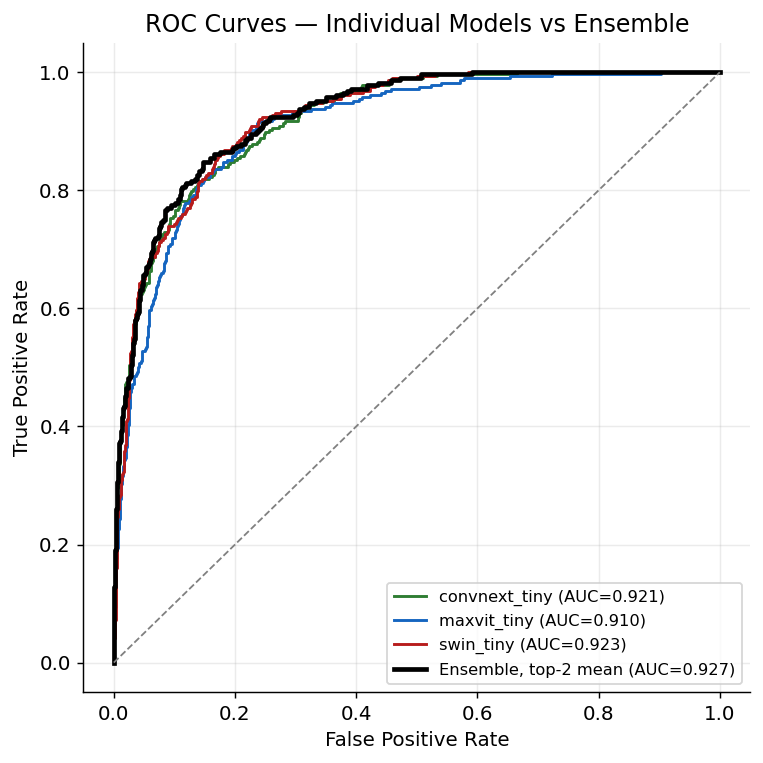

Saved figures/fig05_roc_curves.png


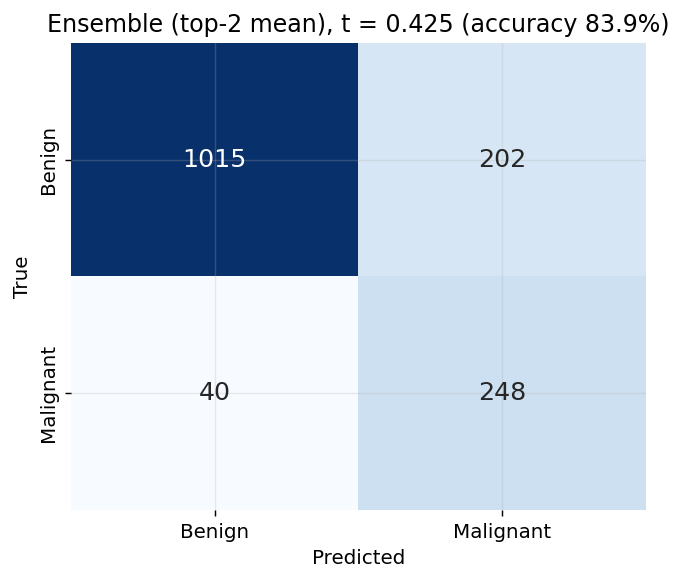

Saved figures/fig06_confusion_matrix.png


In [9]:
fig,ax=plt.subplots(figsize=(6,6))
for k in model_names:
    fpr,tpr,_=roc_curve(L_te,per_te[k])
    ax.plot(fpr,tpr,label=f"{k} (AUC={aucs[k]:.3f})",linewidth=1.6,color=colors.get(k))
fpr,tpr,_=roc_curve(L_te,ens_te)
ax.plot(fpr,tpr,label=f"Ensemble, {ENS_LABEL} (AUC={ens_auc:.3f})",linewidth=2.6,color="black")
ax.plot([0,1],[0,1],"--",color="gray",linewidth=1)
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curves — Individual Models vs Ensemble")
ax.legend(loc="lower right",fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR+"fig05_roc_curves.png",bbox_inches="tight")
plt.show()
print("Saved figures/fig05_roc_curves.png")

cm=confusion_matrix(L_te,preds)
fig,ax=plt.subplots(figsize=(5.2,4.6))
sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",cbar=False,
            xticklabels=["Benign","Malignant"],yticklabels=["Benign","Malignant"],ax=ax,annot_kws={"size":14})
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title(f"Ensemble ({ENS_LABEL}), t = {best_thr:.3f} (accuracy {acc*100:.1f}%)")
fig.tight_layout()
fig.savefig(FIG_DIR+"fig06_confusion_matrix.png",bbox_inches="tight")
plt.show()
print("Saved figures/fig06_confusion_matrix.png")

## 10. Figure: model comparison

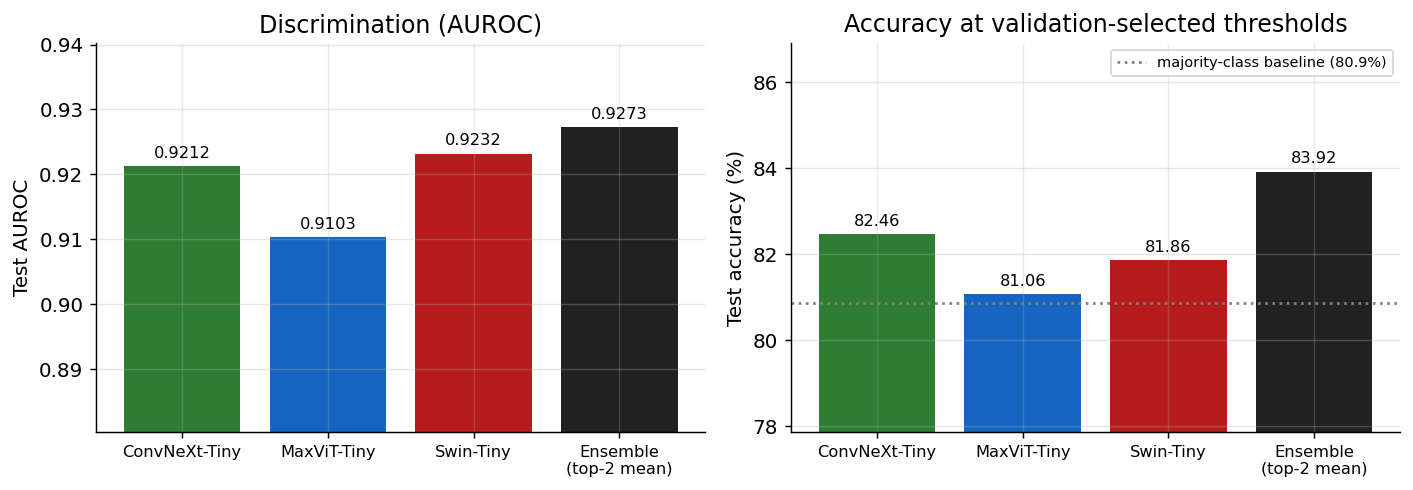

Saved figures/fig07_model_comparison.png


In [10]:
labels = {"convnext_tiny": "ConvNeXt-Tiny", "maxvit_tiny": "MaxViT-Tiny", "swin_tiny": "Swin-Tiny"}
names = [labels.get(k, k) for k in model_names] + [f"Ensemble\n({ENS_LABEL})"]
auc_vals = [aucs[k] for k in model_names] + [ens_auc]
acc_vals = [per_model_test[k][0] * 100 for k in model_names] + [acc * 100]
cols = [colors.get(k, "#888") for k in model_names] + ["#212121"]
base = (1 - L_te.mean()) * 100
fig, ax = plt.subplots(1, 2, figsize=(11, 3.9))
b = ax[0].bar(range(len(names)), auc_vals, color=cols)
ax[0].bar_label(b, labels=[f"{v:.4f}" for v in auc_vals], padding=3, fontsize=9)
ax[0].set_ylim(min(auc_vals) - 0.03, max(auc_vals) + 0.013)
ax[0].set_ylabel("Test AUROC"); ax[0].set_title("Discrimination (AUROC)")
b = ax[1].bar(range(len(names)), acc_vals, color=cols)
ax[1].bar_label(b, labels=[f"{v:.2f}" for v in acc_vals], padding=3, fontsize=9)
ax[1].axhline(base, ls=":", c="gray", label=f"majority-class baseline ({base:.1f}%)")
ax[1].set_ylim(min(acc_vals + [base]) - 3, max(acc_vals) + 3)
ax[1].set_ylabel("Test accuracy (%)"); ax[1].set_title("Accuracy at validation-selected thresholds")
ax[1].legend(fontsize=8, loc="upper right")
for a in ax:
    a.set_xticks(range(len(names))); a.set_xticklabels(names, fontsize=9)
    a.spines[["top", "right"]].set_visible(False); a.grid(axis="y", alpha=0.3)
fig.tight_layout(); fig.savefig(FIG_DIR + "fig07_model_comparison.png", bbox_inches="tight"); plt.show()
print("Saved figures/fig07_model_comparison.png")

## 11. Grad-CAM

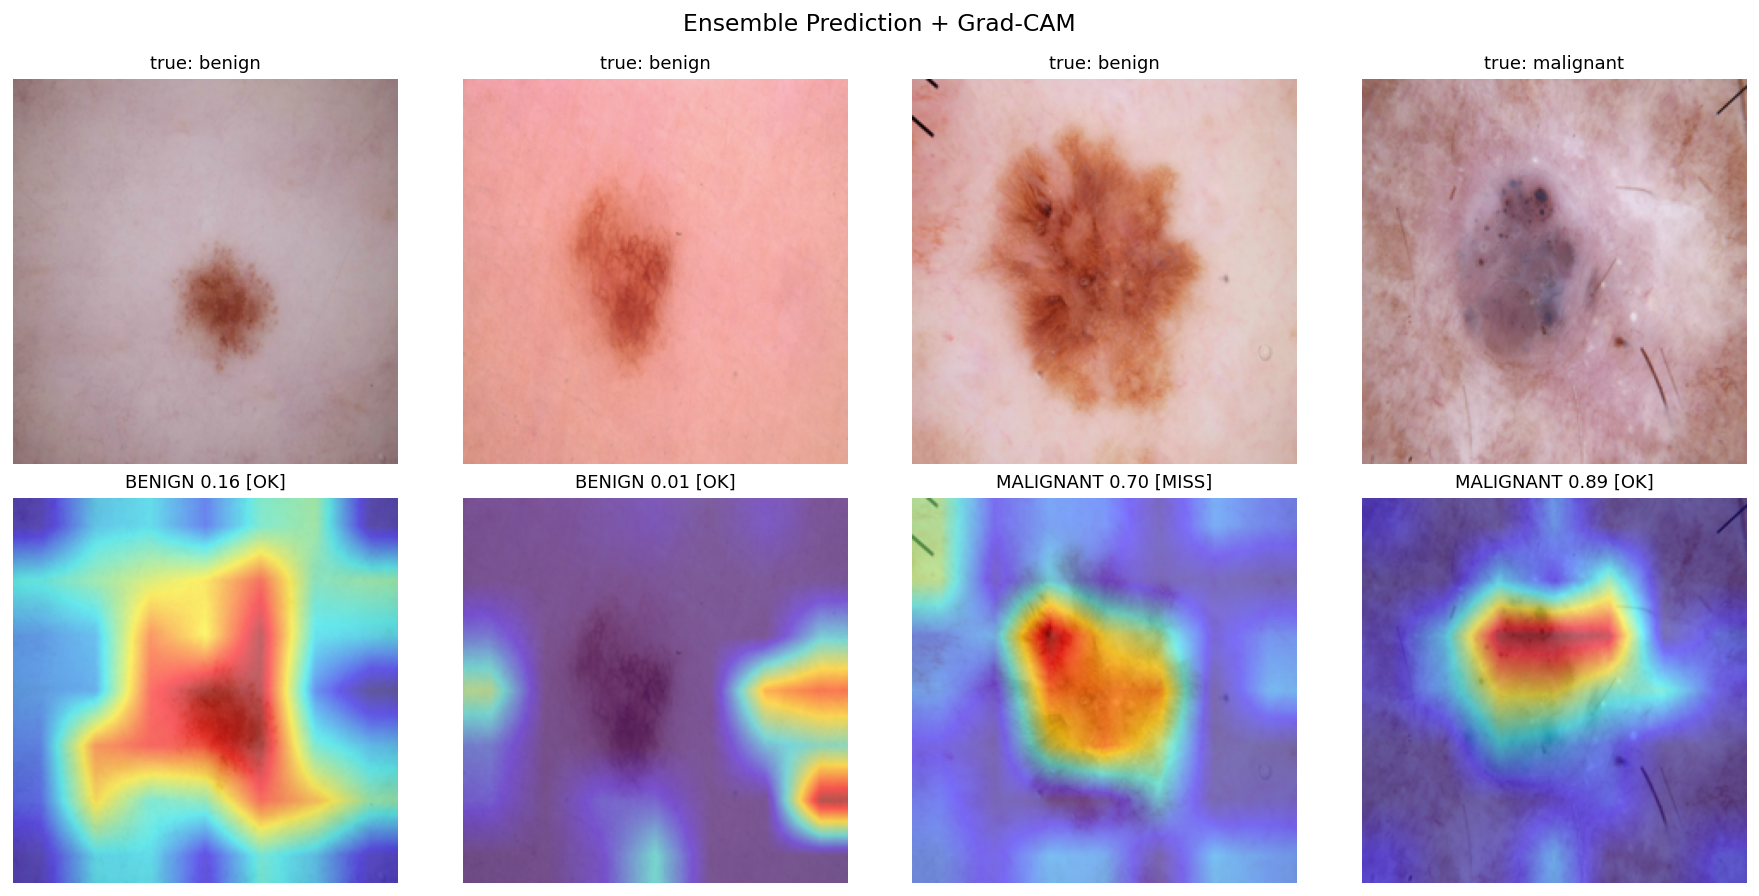

Grad-CAM demo saved.


In [11]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

def target_layer(mname,model):
    bb=model.backbone
    if "convnext" in mname:  return [bb.stages[-1].blocks[-1].conv_dw]
    if "maxvit" in mname:    return [bb.stages[-1].blocks[-1]]
    if "swin" in mname:      return [bb.layers[-1].blocks[-1].norm2]
    return [list(bb.modules())[-1]]

def swin_reshape(t,h=7,w=7):
    return t.reshape(t.size(0),h,w,t.size(2)).permute(0,3,1,2)

def gradcam(pil,mname):
    model=ENS_MODELS[mname]
    x=eval_tfm(pil).unsqueeze(0).to(DEVICE)
    kw={"reshape_transform":swin_reshape} if "swin" in mname else {}
    cam=GradCAM(model=model,target_layers=target_layer(mname,model),**kw)
    g=cam(input_tensor=x,targets=[ClassifierOutputTarget(1)])[0]
    rgb=np.array(pil.resize((IMG_SIZE,IMG_SIZE)),dtype=np.float32)/255.0
    return show_cam_on_image(rgb,g,use_rgb=True)

def ensemble_prob(probs):
    xrow=np.array([[probs[k] for k in model_names]])
    c=deploy_cfg["combiner"]
    if c=="stacking": return float(meta.predict_proba(xrow)[0,1])
    if c=="weighted": return float((xrow*np.array(w)).sum()/np.sum(w))
    if c=="top2":     return float(np.mean([probs[k] for k in top2]))
    return float(xrow.mean())

def predict_and_explain(image_path, cam_model="swin_tiny"):
    pil=Image.open(image_path).convert("RGB")
    x=eval_tfm(pil).unsqueeze(0).to(DEVICE)
    views=[x]
    if USE_TTA:
        views += [torch.flip(x,dims=[3]), torch.flip(x,dims=[2]), torch.flip(x,dims=[2,3])]
    with torch.no_grad():
        probs={}
        for k,m in ENS_MODELS.items():
            ps=[torch.softmax(m(v),1)[0,1].item() for v in views]
            probs[k]=float(np.mean(ps))
    ep=ensemble_prob(probs)
    label="MALIGNANT" if ep>=deploy_cfg["threshold"] else "BENIGN"
    overlay=gradcam(pil,cam_model)
    return ep,label,overlay,pil,probs

demo=pd.read_csv(SPLITS_DIR+"ham_test.csv").sample(4,random_state=7)
fig,axes=plt.subplots(2,4,figsize=(14,7))
for j,(_,r) in enumerate(demo.iterrows()):
    ep,label,overlay,orig,_=predict_and_explain(HAM_LOOKUP[r["image_name"]])
    truth="malignant" if r["target"]==1 else "benign"
    ok="OK" if (label=="MALIGNANT")==(r["target"]==1) else "MISS"
    axes[0,j].imshow(orig.resize((IMG_SIZE,IMG_SIZE))); axes[0,j].set_title(f"true: {truth}",fontsize=10); axes[0,j].axis("off")
    axes[1,j].imshow(overlay); axes[1,j].set_title(f"{label} {ep:.2f} [{ok}]",fontsize=10); axes[1,j].axis("off")
fig.suptitle("Ensemble Prediction + Grad-CAM",fontsize=13)
fig.tight_layout(); fig.savefig(FIG_DIR+"fig09_gradcam.png",dpi=150,bbox_inches="tight"); plt.show()
print("Grad-CAM demo saved.")

## 12. Model weight packaging

In [12]:
import shutil
art = SAVE_DIR + "deploy_artifacts/"; os.makedirs(art, exist_ok=True)
for k in MODELS:
    shutil.copy(SAVE_DIR + f"model_{k}.pth", art + f"model_{k}.pth")
shutil.copy(SAVE_DIR + "deploy_config.json", art + "deploy_config.json")
shutil.make_archive(SAVE_DIR + "skin_cancer_deploy", "zip", art)
print("Packaged:", SAVE_DIR + "skin_cancer_deploy.zip")

Packaged: /kaggle/working/skin_cancer_deploy.zip


## 13. Calibration (temperature scaling)

Validation split -> tune 750 | calibration 750
Malignant rate   -> tune 18.0% | cal 21.6%

Optimal temperature (tune half only): T = 0.702
                             ECE     Brier       NLL     AUROC
uncalibrated              0.0308    0.0940    0.2959    0.9273
temperature-scaled        0.0277    0.0944    0.2969    0.9273


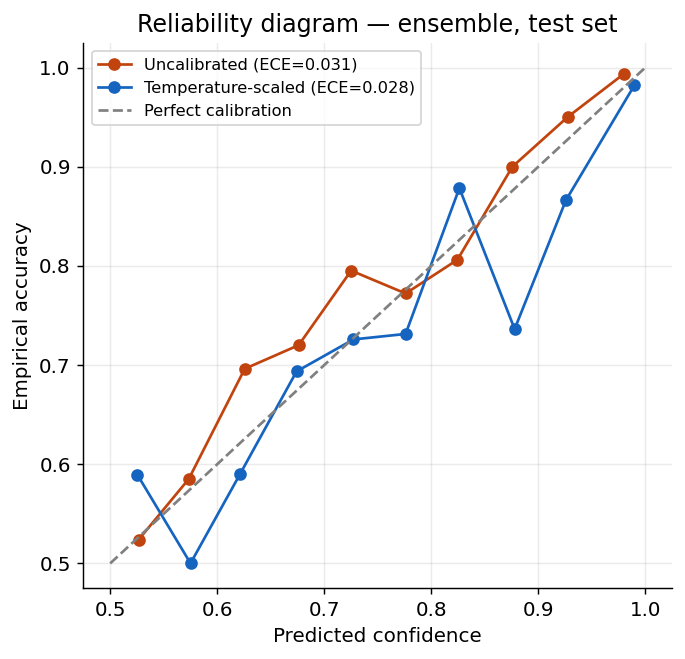

Saved figures/fig11_reliability.png


In [13]:
from scipy.optimize import minimize_scalar, differential_evolution
from scipy.stats import norm, beta as beta_dist

_rng = np.random.RandomState(SEED)
_perm = _rng.permutation(len(L_va))
CAL_IDX  = _perm[: len(_perm) // 2]
TUNE_IDX = _perm[len(_perm) // 2:]
print(f"Validation split -> tune {len(TUNE_IDX)} | calibration {len(CAL_IDX)}")
print(f"Malignant rate   -> tune {L_va[TUNE_IDX].mean()*100:.1f}% | cal {L_va[CAL_IDX].mean()*100:.1f}%")

def _logit(p, eps=1e-6):
    p = np.clip(p, eps, 1 - eps)
    return np.log(p / (1 - p))

def apply_temperature(p, T):
    return 1.0 / (1.0 + np.exp(-_logit(p) / T))

def nll(y, p, eps=1e-9):
    p = np.clip(p, eps, 1 - eps)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

def ece(y, p, n_bins=15):
    conf = np.maximum(p, 1 - p)
    correct = ((p >= 0.5).astype(int) == y).astype(float)
    bins = np.linspace(0.5, 1.0, n_bins + 1)
    e = 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum():
            e += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return e

def brier(y, p):
    return np.mean((p - y) ** 2)

_res = minimize_scalar(lambda T: nll(L_va[TUNE_IDX], apply_temperature(ens_va[TUNE_IDX], T)),
                       bounds=(0.25, 8.0), method="bounded")
T_OPT = float(_res.x)
ens_te_cal = apply_temperature(ens_te, T_OPT)

print(f"\nOptimal temperature (tune half only): T = {T_OPT:.3f}")
print(f"{'':22}{'ECE':>10}{'Brier':>10}{'NLL':>10}{'AUROC':>10}")
for name, p in [("uncalibrated", ens_te), ("temperature-scaled", ens_te_cal)]:
    print(f"{name:22}{ece(L_te,p):>10.4f}{brier(L_te,p):>10.4f}{nll(L_te,p):>10.4f}{roc_auc_score(L_te,p):>10.4f}")

fig, ax = plt.subplots(figsize=(5.4, 5.2))
for p, lab, c in [(ens_te, "Uncalibrated", "#C1440E"), (ens_te_cal, "Temperature-scaled", "#1565C0")]:
    conf = np.maximum(p, 1 - p)
    correct = ((p >= 0.5).astype(int) == L_te).astype(float)
    bins = np.linspace(0.5, 1.0, 11)
    xs, ys = [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() > 5:
            xs.append(conf[m].mean()); ys.append(correct[m].mean())
    ax.plot(xs, ys, marker="o", color=c, label=f"{lab} (ECE={ece(L_te,p):.3f})")
ax.plot([0.5, 1], [0.5, 1], "--", color="gray", label="Perfect calibration")
ax.set_xlabel("Predicted confidence"); ax.set_ylabel("Empirical accuracy")
ax.set_title("Reliability diagram — ensemble, test set")
ax.legend(fontsize=9, loc="upper left")
fig.tight_layout(); fig.savefig(FIG_DIR + "fig11_reliability.png", bbox_inches="tight"); plt.show()
print("Saved figures/fig11_reliability.png")

## 14. Soft-computing fusion (differential evolution, Choquet integral)

In [14]:
X_va = np.stack([per_va[k] for k in model_names], 1)
X_te = np.stack([per_te[k] for k in model_names], 1)
n_m = len(model_names)
Xt, Lt = X_va[TUNE_IDX], L_va[TUNE_IDX]

def de_objective(w):
    w = np.abs(w)
    if w.sum() < 1e-8:
        return 0.0
    w = w / w.sum()
    p = Xt @ w
    t = best_threshold_balanced(Lt, p)
    _, _, _, bal = metrics_at(Lt, p, t)
    return -(0.5 * roc_auc_score(Lt, p) + 0.5 * bal)

de_hist = []
def de_cb(xk, convergence=None):
    de_hist.append(-de_objective(xk))
de = differential_evolution(de_objective, bounds=[(0.0, 1.0)] * n_m,
                            seed=SEED, maxiter=60, tol=1e-6, polish=True, callback=de_cb)
W_DE = np.abs(de.x) / np.abs(de.x).sum()
print("DE-optimised weights:", {k: round(float(w), 4) for k, w in zip(model_names, W_DE)})
print(f"DE converged in {de.nit} generations | objective {-de.fun:.4f}")

def sugeno_lambda(g):
    f = lambda lam: np.prod(1.0 + lam * g) - (1.0 + lam)
    s = g.sum()
    if abs(s - 1.0) < 1e-6:
        return 0.0
    lo, hi = (1e-9, 100.0) if s < 1.0 else (-1.0 + 1e-9, -1e-9)
    if f(lo) * f(hi) > 0:
        print("  warning: no sign change, falling back to additive measure")
        return 0.0
    for _ in range(300):
        mid = 0.5 * (lo + hi)
        if f(lo) * f(mid) <= 0:
            hi = mid
        else:
            lo = mid
    return 0.5 * (lo + hi)

g_dens = np.array([max(roc_auc_score(Lt, Xt[:, i]) - 0.5, 1e-3) for i in range(n_m)])
g_dens = g_dens / g_dens.sum() * 0.9
LAM = sugeno_lambda(g_dens)
print(f"Sugeno lambda = {LAM:.4f} (sum of densities = {g_dens.sum():.3f})")
print("Fuzzy densities:", {k: round(float(v), 4) for k, v in zip(model_names, g_dens)})
mu_full = (np.prod(1 + LAM * g_dens) - 1) / LAM if abs(LAM) > 1e-8 else g_dens.sum()
print(f"Sanity check: measure of the full set = {mu_full:.4f} (should be 1.000)")

def choquet(X, g, lam):
    idx = np.argsort(X, axis=1)
    Xs = np.take_along_axis(X, idx, axis=1)
    gs = g[idx]
    out = np.zeros(len(X)); prev = np.zeros(len(X))
    for i in range(X.shape[1]):
        tail = gs[:, i:]
        mu = tail.sum(1) if abs(lam) < 1e-8 else (np.prod(1.0 + lam * tail, axis=1) - 1.0) / lam
        mu = np.clip(mu, 0.0, 1.0)
        out += (Xs[:, i] - prev) * mu
        prev = Xs[:, i]
    return np.clip(out, 0, 1)

meta_tune = LogisticRegression(max_iter=1000, class_weight="balanced").fit(Xt, Lt)
fusion = {
    "average":          (X_va.mean(1), X_te.mean(1)),
    "stacking (LR)":    (meta_tune.predict_proba(X_va)[:, 1], meta_tune.predict_proba(X_te)[:, 1]),
    "DE-weighted":      (X_va @ W_DE, X_te @ W_DE),
    "Choquet (Sugeno)": (choquet(X_va, g_dens, LAM), choquet(X_te, g_dens, LAM)),
}
rows = []
for name, (pv, pt) in fusion.items():
    t = best_threshold_balanced(Lt, pv[TUNE_IDX])
    _, _, _, val_bal = metrics_at(Lt, pv[TUNE_IDX], t)
    a, se, sp, bal = metrics_at(L_te, pt, t)
    rows.append(dict(fusion=name, thr=round(t, 3), val_bal_acc=val_bal,
                     test_auroc=roc_auc_score(L_te, pt), test_acc=a,
                     test_sens=se, test_spec=sp, test_bal_acc=bal))
fusion_df = pd.DataFrame(rows).sort_values("val_bal_acc", ascending=False)
display(fusion_df.round(4))
fusion_df.to_csv(SAVE_DIR + "fusion_comparison.csv", index=False)

BEST_FUSION = fusion_df.iloc[0].fusion
p_va_f, p_te_f = fusion[BEST_FUSION]
print(f"\nSelected fusion operator (by validation balanced accuracy): {BEST_FUSION}")
print(f"Its test balanced accuracy: {fusion_df.iloc[0].test_bal_acc*100:.2f}% (out of sample)")

DE-optimised weights: {'convnext_tiny': 0.2703, 'maxvit_tiny': 0.211, 'swin_tiny': 0.5187}
DE converged in 60 generations | objective 0.9212
Sugeno lambda = 0.3576 (sum of densities = 0.900)
Fuzzy densities: {'convnext_tiny': 0.3005, 'maxvit_tiny': 0.3005, 'swin_tiny': 0.299}
Sanity check: measure of the full set = 1.0000 (should be 1.000)


,fusion,thr,val_bal_acc,test_auroc,test_acc,test_sens,test_spec,test_bal_acc
2,DE-weighted,0.38,0.8932,0.9308,0.8013,0.9062,0.7765,0.8414
3,Choquet (Sugeno),0.38,0.8874,0.9306,0.8120,0.8854,0.7946,0.8400
1,stacking (LR),0.43,0.8869,0.9309,0.8126,0.8819,0.7962,0.8391
0,average,0.39,0.8865,0.9309,0.8120,0.8854,0.7946,0.8400



Selected fusion operator (by validation balanced accuracy): DE-weighted
Its test balanced accuracy: 84.14% (out of sample)


## 15. Figure: fusion

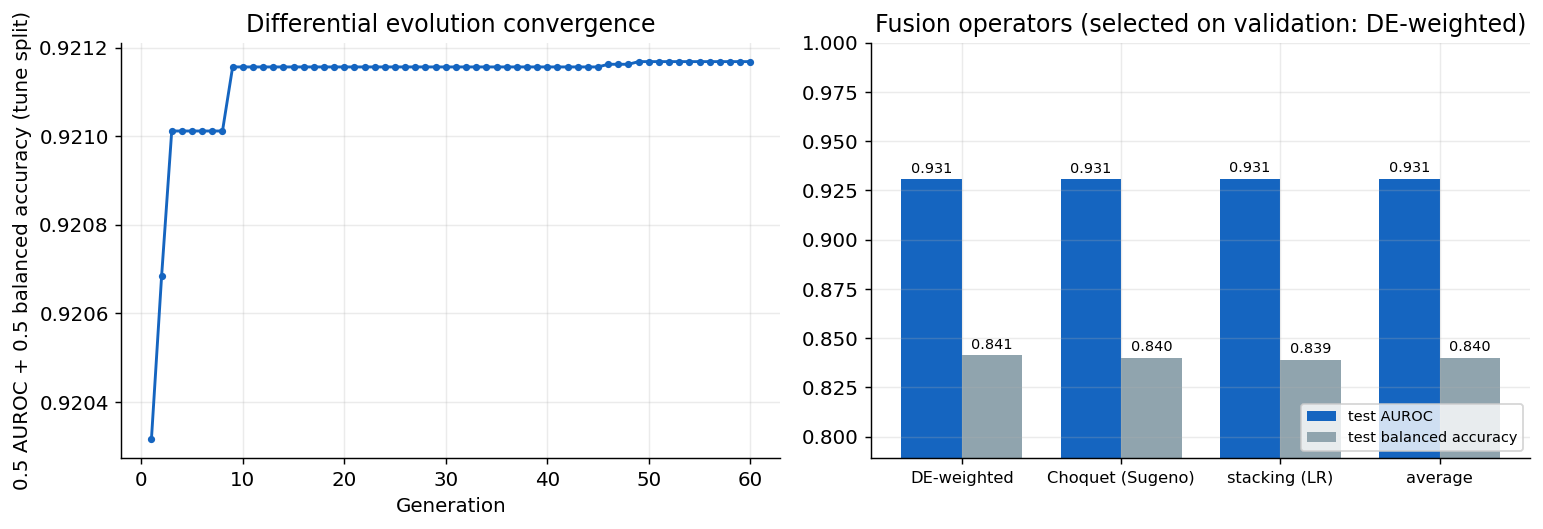

Saved figures/fig12_fusion_de.png


In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(range(1, len(de_hist) + 1), de_hist, "o-", ms=3, lw=1.6, color="#1565C0")
ax[0].set_xlabel("Generation"); ax[0].set_ylabel("0.5 AUROC + 0.5 balanced accuracy (tune split)")
ax[0].set_title("Differential evolution convergence")
f = fusion_df.set_index("fusion")
xs = np.arange(len(f)); w = 0.38
b1 = ax[1].bar(xs - w/2, f.test_auroc, w, label="test AUROC", color="#1565C0")
b2 = ax[1].bar(xs + w/2, f.test_bal_acc, w, label="test balanced accuracy", color="#90A4AE")
ax[1].bar_label(b1, fmt="%.3f", fontsize=8, padding=2); ax[1].bar_label(b2, fmt="%.3f", fontsize=8, padding=2)
ax[1].set_xticks(xs); ax[1].set_xticklabels(f.index, fontsize=9)
ax[1].set_ylim(min(f.test_bal_acc.min(), f.test_auroc.min()) - 0.05, 1.0)
ax[1].set_title(f"Fusion operators (selected on validation: {BEST_FUSION})")
ax[1].legend(fontsize=8, loc="lower right")
fig.tight_layout(); fig.savefig(FIG_DIR + "fig12_fusion_de.png", bbox_inches="tight"); plt.show()
print("Saved figures/fig12_fusion_de.png")

## 16. Fuzzy triage with conformal risk control

In [16]:
ALPHA = 0.10
DELTA = 0.05

thr_star = best_threshold_balanced(L_va[TUNE_IDX], p_va_f[TUNE_IDX])
print(f"Decision threshold (tune half): {thr_star:.3f}")

def trimf(x, a, b, c):
    return np.clip(np.minimum((x - a) / (b - a + 1e-9), (c - x) / (c - b + 1e-9)), 0, 1)

CONF_MODES = ("margin", "entropy", "expected_error")
FUZZY_CONF = "margin"

def conf_input(p, thr, mode):
    """Confidence in [0, 1] (1 = certain) fed to the fuzzy system."""
    if mode == "entropy":
        pc = np.clip(p, 1e-6, 1 - 1e-6)
        return np.clip(1 + (pc * np.log(pc) + (1 - pc) * np.log(1 - pc)) / np.log(2), 0, 1)
    if mode == "expected_error":
        e = np.where(p >= thr, 1 - p, p)
        return np.clip(1 - e / max(thr, 1 - thr), 0, 1)
    return np.clip(np.abs(p - thr) / max(thr, 1 - thr), 0, 1)

HANDSET = dict(cmf=[(-0.4, 0.0, 0.4), (0.15, 0.45, 0.75), (0.5, 1.0, 1.4)],
               dmf=[(-0.4, 0.0, 0.4), (0.15, 0.45, 0.75), (0.5, 1.0, 1.4)],
               Z=[[0.75, 0.90, 1.00],
                  [0.25, 0.50, 0.80],
                  [0.00, 0.20, 0.45]],
               dscale=0.5)
FIS_PARAMS = HANDSET

def fis(conf, dis, P):
    c = [trimf(conf, *t) for t in P["cmf"]]; d = [trimf(dis, *t) for t in P["dmf"]]
    num, den = 0.0, 0.0
    for i in range(3):
        for j in range(3):
            w = np.minimum(c[i], d[j]); num = num + w * P["Z"][i][j]; den = den + w
    return num / (den + 1e-9)

def fuzzy_defer_degree(p, X, thr, mode=None, P=None):
    P = P or FIS_PARAMS
    return fis(conf_input(p, thr, mode or FUZZY_CONF), np.clip(X.std(1) / P["dscale"], 0, 1), P)

def cp_upper(k, n, delta=DELTA):
    return 1.0 if k >= n else float(beta_dist.ppf(1 - delta, k + 1, n - k))

N_MIN = 100

def select_cutoff(scores_cal, y_cal, p_cal, thr, alpha=ALPHA, delta=DELTA):
    """Learn-then-Test with fixed-sequence testing: cut-offs are tested from the most
    conservative upwards (order fixed by the scores, not the labels) and testing stops at
    the first failure, so the returned cut-off keeps the (1 - DELTA) guarantee."""
    best_tau, best_cov = 0.0, 0.0
    for tau in np.linspace(0.0, 1.0, 201):
        keep = scores_cal < tau
        n = int(keep.sum())
        if n < N_MIN:
            continue
        err = int((((p_cal[keep] >= thr).astype(int)) != y_cal[keep]).sum())
        if cp_upper(err, n, delta) > alpha:
            break
        best_tau, best_cov = tau, keep.mean()
    return best_tau, best_cov

def balanced_selective_risk(score, y, p, t, covs=np.arange(0.50, 1.001, 0.05)):
    """Mean balanced error (1 - (sens + spec) / 2) of the kept cases over coverage 50-100%.
    Balanced, so referring cancers to keep easy benign cases is not rewarded."""
    o = np.argsort(score, kind="stable"); yy, pr = y[o], (p[o] >= t).astype(int)
    out = []
    for c in covs:
        k = max(int(round(c * len(yy))), 1); a, b = yy[:k], pr[:k]
        se = ((b == 1) & (a == 1)).sum() / max((a == 1).sum(), 1)
        sp = ((b == 0) & (a == 0)).sum() / max((a == 0).sum(), 1)
        out.append(1 - (se + sp) / 2)
    return float(np.mean(out))

tune_risk = {m: balanced_selective_risk(fuzzy_defer_degree(p_va_f[TUNE_IDX], X_va[TUNE_IDX], thr_star, m),
                                        L_va[TUNE_IDX], p_va_f[TUNE_IDX], thr_star) for m in CONF_MODES}
FUZZY_CONF = min(tune_risk, key=tune_risk.get)
print("Fuzzy confidence input, balanced selective risk on tune split:",
      {m: round(v, 4) for m, v in tune_risk.items()}, "-> selected:", FUZZY_CONF)

fz_cal = fuzzy_defer_degree(p_va_f[CAL_IDX], X_va[CAL_IDX], thr_star)
TAU, cov_cal = select_cutoff(fz_cal, L_va[CAL_IDX], p_va_f[CAL_IDX], thr_star)
if TAU == 0.0:
    print(f"WARNING: no cut-off met alpha={ALPHA} on calibration. Raise ALPHA or widen the rule base.")

fz_te = fuzzy_defer_degree(p_te_f, X_te, thr_star)
keep_te = fz_te < TAU
if keep_te.sum() == 0:
    print("WARNING: zero coverage on test — check TAU.")
else:
    sel_pred = (p_te_f[keep_te] >= thr_star).astype(int)
    sel_err = (sel_pred != L_te[keep_te]).mean()
    full_acc = ((p_te_f >= thr_star).astype(int) == L_te).mean()
    tn, fp, fn, tp = confusion_matrix(L_te[keep_te], sel_pred, labels=[0, 1]).ravel()
    print(f"\nHand-set fuzzy cut-off  : {TAU:.3f}  (selected on calibration half of val)")
    print(f"Guarantee               : selective error <= {ALPHA:.0%} with {1-DELTA:.0%} confidence")
    print(f"Calibration coverage    : {cov_cal*100:.1f}%")
    print(f"TEST coverage           : {keep_te.mean()*100:.1f}%  ({keep_te.sum()}/{len(L_te)} auto-reported)")
    print(f"TEST selective error    : {sel_err*100:.2f}%   (guarantee held: {sel_err <= ALPHA})")
    print(f"TEST selective accuracy : {(1-sel_err)*100:.2f}%  vs {full_acc*100:.2f}% under forced prediction")
    wrong_te = (p_te_f >= thr_star).astype(int) != L_te
    print(f"Deferred                : {(~keep_te).sum()} cases, {L_te[~keep_te].mean()*100:.1f}% malignant "
          f"(base rate {L_te.mean()*100:.1f}%)")
    print(f"Error rate              : {wrong_te[~keep_te].mean()*100:.1f}% among referred vs "
          f"{wrong_te[keep_te].mean()*100:.1f}% among auto-reported")
    print(f"Auto-reported sens/spec : {tp/(tp+fn+1e-9)*100:.1f}% / {tn/(tn+fp+1e-9)*100:.1f}%")

    deploy_cfg.update(dict(fusion=BEST_FUSION, temperature=round(T_OPT, 4),
                           de_weights={k: round(float(w), 4) for k, w in zip(model_names, W_DE)},
                           sugeno_lambda=round(float(LAM), 4),
                           fuzzy_densities={k: round(float(v), 4) for k, v in zip(model_names, g_dens)},
                           threshold=round(float(thr_star), 4), fuzzy_tau=round(float(TAU), 4),
                           fuzzy_conf=FUZZY_CONF,
                           alpha=ALPHA, delta=DELTA,
                           test_coverage=round(float(keep_te.mean()), 4),
                           test_selective_error=round(float(sel_err), 4)))
    with open(SAVE_DIR + "deploy_config.json", "w") as f:
        json.dump(deploy_cfg, f, indent=2)
    print("\nUpdated deploy_config.json")

abl_rows = []
for m in CONF_MODES:
    t_m, c_m = select_cutoff(fuzzy_defer_degree(p_va_f[CAL_IDX], X_va[CAL_IDX], thr_star, m),
                             L_va[CAL_IDX], p_va_f[CAL_IDX], thr_star)
    k = fuzzy_defer_degree(p_te_f, X_te, thr_star, m) < t_m
    pr, yy = (p_te_f[k] >= thr_star).astype(int), L_te[k]
    abl_rows.append(dict(confidence_input=m, selected=(m == FUZZY_CONF), tau=round(t_m, 3),
                         test_coverage=k.mean(), selective_acc=(pr == yy).mean() if k.any() else np.nan,
                         auto_sens=((pr == 1) & (yy == 1)).sum() / max((yy == 1).sum(), 1),
                         auto_spec=((pr == 0) & (yy == 0)).sum() / max((yy == 0).sum(), 1),
                         referred_malignant_rate=L_te[~k].mean() if (~k).any() else np.nan))
fuzzy_ablation = pd.DataFrame(abl_rows)
display(fuzzy_ablation.round(4))
fuzzy_ablation.to_csv(SAVE_DIR + "fuzzy_input_ablation.csv", index=False)

print("\nMembership-breakpoint sensitivity (test coverage / selective error):")
def _shifted(P, sh):
    lo, md, hi = P["cmf"]
    t = [(lo[0], lo[1], lo[2] + sh), (md[0] + sh, md[1] + sh, md[2] + sh), (hi[0] + sh, hi[1], hi[2])]
    return dict(cmf=t, dmf=t, Z=P["Z"], dscale=P["dscale"])
for shift in (-0.10, -0.05, 0.0, 0.05, 0.10):
    Ps = _shifted(HANDSET, shift)
    t_s, _ = select_cutoff(fuzzy_defer_degree(p_va_f[CAL_IDX], X_va[CAL_IDX], thr_star, P=Ps),
                           L_va[CAL_IDX], p_va_f[CAL_IDX], thr_star)
    k_s = fuzzy_defer_degree(p_te_f, X_te, thr_star, P=Ps) < t_s
    e_s = ((p_te_f[k_s] >= thr_star).astype(int) != L_te[k_s]).mean() if k_s.sum() else np.nan
    print(f"   breakpoints {shift:+.2f} -> tau {t_s:.3f} | coverage {k_s.mean()*100:5.1f}% | sel. error {e_s*100:5.2f}%")

Decision threshold (tune half): 0.380
Fuzzy confidence input, balanced selective risk on tune split: {'margin': 0.0636, 'entropy': 0.0507, 'expected_error': 0.0488} -> selected: expected_error

Hand-set fuzzy cut-off  : 0.405  (selected on calibration half of val)
Guarantee               : selective error <= 10% with 95% confidence
Calibration coverage    : 81.5%
TEST coverage           : 81.3%  (1224/1505 auto-reported)
TEST selective error    : 8.91%   (guarantee held: True)
TEST selective accuracy : 91.09%  vs 80.13% under forced prediction
Deferred                : 281 cases, 24.2% malignant (base rate 19.1%)
Error rate              : 67.6% among referred vs 8.9% among auto-reported
Auto-reported sens/spec : 90.0% / 91.3%

Updated deploy_config.json


,confidence_input,selected,tau,test_coverage,selective_acc,auto_sens,auto_spec,referred_malignant_rate
0,margin,False,0.345,0.6757,0.9154,0.9466,0.9075,0.1680
1,entropy,False,0.755,0.7927,0.8977,0.9194,0.8931,0.2468
2,expected_error,True,0.405,0.8133,0.9109,0.9000,0.9133,0.2420



Membership-breakpoint sensitivity (test coverage / selective error):
   breakpoints -0.10 -> tau 0.395 | coverage  81.6% | sel. error  9.28%
   breakpoints -0.05 -> tau 0.400 | coverage  81.3% | sel. error  9.08%
   breakpoints +0.00 -> tau 0.405 | coverage  81.3% | sel. error  8.91%
   breakpoints +0.05 -> tau 0.405 | coverage  80.9% | sel. error  8.29%
   breakpoints +0.10 -> tau 0.465 | coverage  82.4% | sel. error  8.71%


## 17. Evolutionary fuzzy triage

DE finished: 100 generations | tune balanced risk 0.0455
Disagreement scale: hand-set 0.5 -> evolved 0.081
Evolved rule outputs (rows: confidence low/med/high, cols: disagreement low/med/high):
    [0.64, 0.678, 0.706]
    [0.445, 0.483, 0.511]
    [0.344, 0.382, 0.41]


,router,tune_bal_risk,cal_bal_risk,test_bal_risk,tau,cal_coverage,coverage,selective_acc,sens,spec,missed_cancers,auto_benign_cancer_rate,guarantee_held
0,margin only,0.0659,0.0764,0.0914,0.000,0.0000,0.0000,NaN,0.0000,0.0000,0,0.0000,True
1,entropy only,0.0486,0.0619,0.0854,0.955,0.8347,0.8359,0.9134,0.8846,0.9199,27,0.0279,True
2,disagreement only,0.0619,0.0776,0.0995,0.160,0.6760,0.7130,0.9003,0.9333,0.8936,12,0.0148,True
3,"fuzzy, hand-set",0.0488,0.0632,0.0874,0.405,0.8147,0.8133,0.9109,0.9000,0.9133,22,0.0234,True
4,"fuzzy, evolutionary",0.0455,0.0621,0.0867,0.525,0.8427,0.8485,0.9092,0.8889,0.9139,27,0.0278,True


Cancers in test set: 288. missed_cancers = auto-reported benign, never referred.

Calibration coverage at DELTA/2: hand-set 79.6% | evolved 83.6%  -> deployed: fuzzy, evolutionary
Deployed router on TEST: tau 0.515 | coverage 83.7% | selective accuracy 91.27% | sens 88.5% | spec 91.9% | missed cancers 27/288 | guarantee held: True


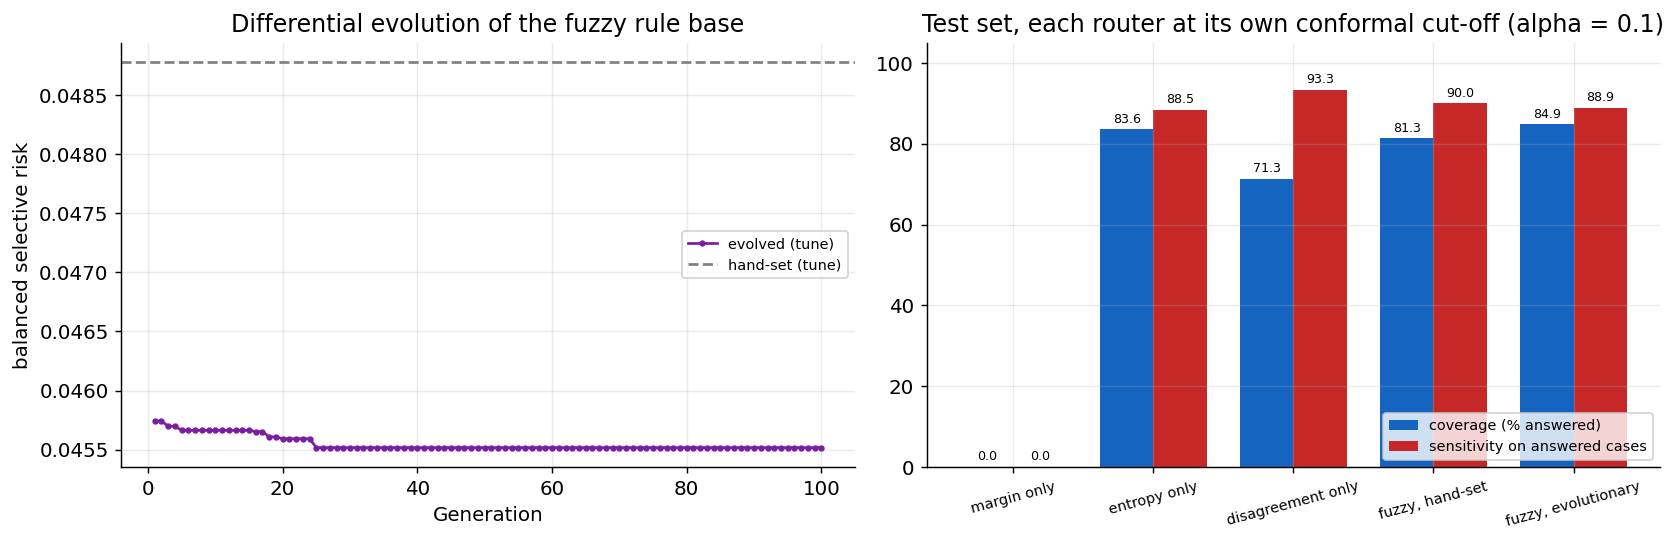

Saved figures/fig13b_fuzzy_evolution.png


In [17]:
def params_from_theta(th):
    u = np.sort(th[1:4])[::-1]
    v = np.sort(th[4:7])
    return dict(cmf=HANDSET["cmf"], dmf=HANDSET["dmf"], dscale=float(th[0]),
                Z=[[float((u[i] + v[j]) / 2) for j in range(3)] for i in range(3)])

EVO_BOUNDS = [(0.05, 0.5)] + [(0.0, 1.0)] * 6
def evo_objective(th):
    s = fuzzy_defer_degree(p_va_f[TUNE_IDX], X_va[TUNE_IDX], thr_star, P=params_from_theta(th))
    return balanced_selective_risk(s, L_va[TUNE_IDX], p_va_f[TUNE_IDX], thr_star)

evo_hist = []
def _evo_cb(xk, convergence=None):
    evo_hist.append(evo_objective(xk))
evo = differential_evolution(evo_objective, EVO_BOUNDS, seed=SEED, maxiter=100, popsize=20,
                             tol=1e-8, polish=False, callback=_evo_cb)
P_EVO = params_from_theta(evo.x)
print(f"DE finished: {evo.nit} generations | tune balanced risk {evo.fun:.4f}")
print(f"Disagreement scale: hand-set {HANDSET['dscale']} -> evolved {P_EVO['dscale']:.3f}")
print("Evolved rule outputs (rows: confidence low/med/high, cols: disagreement low/med/high):")
for r in P_EVO["Z"]: print("   ", [round(v, 3) for v in r])

def _single(which):
    def f(p, X):
        if which == "margin":  return 1 - conf_input(p, thr_star, "margin")
        if which == "entropy": return 1 - conf_input(p, thr_star, "entropy")
        return np.clip(X.std(1) / 0.5, 0, 1)
    return f
ROUTERS = {"margin only": _single("margin"), "entropy only": _single("entropy"),
           "disagreement only": _single("disagreement"),
           "fuzzy, hand-set": lambda p, X: fuzzy_defer_degree(p, X, thr_star, P=HANDSET),
           "fuzzy, evolutionary": lambda p, X: fuzzy_defer_degree(p, X, thr_star, P=P_EVO)}
def router_eval(name, f, delta=DELTA):
    s_tu, s_ca, s_te = f(p_va_f[TUNE_IDX], X_va[TUNE_IDX]), f(p_va_f[CAL_IDX], X_va[CAL_IDX]), f(p_te_f, X_te)
    t, cov_c = select_cutoff(s_ca, L_va[CAL_IDX], p_va_f[CAL_IDX], thr_star, delta=delta)
    k = s_te < t; pr, yy = (p_te_f[k] >= thr_star).astype(int), L_te[k]
    fn = int(((pr == 0) & (yy == 1)).sum())
    return dict(router=name,
        tune_bal_risk=balanced_selective_risk(s_tu, L_va[TUNE_IDX], p_va_f[TUNE_IDX], thr_star),
        cal_bal_risk=balanced_selective_risk(s_ca, L_va[CAL_IDX], p_va_f[CAL_IDX], thr_star),
        test_bal_risk=balanced_selective_risk(s_te, L_te, p_te_f, thr_star),
        tau=round(t, 3), cal_coverage=cov_c, coverage=k.mean(),
        selective_acc=(pr == yy).mean() if k.any() else np.nan,
        sens=((pr == 1) & (yy == 1)).sum() / max((yy == 1).sum(), 1),
        spec=((pr == 0) & (yy == 0)).sum() / max((yy == 0).sum(), 1),
        missed_cancers=fn, auto_benign_cancer_rate=fn / max(int((pr == 0).sum()), 1),
        guarantee_held=bool((pr != yy).mean() <= ALPHA) if k.any() else True)
router_df = pd.DataFrame([router_eval(n, f) for n, f in ROUTERS.items()])
display(router_df.round(4))
router_df.to_csv(SAVE_DIR + "router_comparison.csv", index=False)
print(f"Cancers in test set: {int(L_te.sum())}. missed_cancers = auto-reported benign, never referred.")

cand = {n: router_eval(n, ROUTERS[n], delta=DELTA / 2) for n in ("fuzzy, hand-set", "fuzzy, evolutionary")}
pick = "fuzzy, evolutionary" if cand["fuzzy, evolutionary"]["cal_coverage"] > cand["fuzzy, hand-set"]["cal_coverage"] \
       else "fuzzy, hand-set"
if cand[pick]["cal_coverage"] == 0:
    print("WARNING: no fuzzy router met the bound on calibration data at DELTA/2.")
FIS_PARAMS = P_EVO if pick == "fuzzy, evolutionary" else HANDSET
TAU = cand[pick]["tau"]
fz_te = fuzzy_defer_degree(p_te_f, X_te, thr_star)
keep_te = fz_te < TAU
print(f"\nCalibration coverage at DELTA/2: hand-set {cand['fuzzy, hand-set']['cal_coverage']*100:.1f}% | "
      f"evolved {cand['fuzzy, evolutionary']['cal_coverage']*100:.1f}%  -> deployed: {pick}")
c = cand[pick]
print(f"Deployed router on TEST: tau {TAU:.3f} | coverage {c['coverage']*100:.1f}% | selective accuracy "
      f"{c['selective_acc']*100:.2f}% | sens {c['sens']*100:.1f}% | spec {c['spec']*100:.1f}% | "
      f"missed cancers {c['missed_cancers']}/{int(L_te.sum())} | guarantee held: {c['guarantee_held']}")
deploy_cfg.update(dict(fuzzy_tau=round(float(TAU), 4), fuzzy_router=pick, fis_params=FIS_PARAMS,
                       test_coverage=round(float(keep_te.mean()), 4)))
json.dump(deploy_cfg, open(SAVE_DIR + "deploy_config.json", "w"), indent=2)

r = router_df.set_index("router")
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
ax[0].plot(range(1, len(evo_hist) + 1), evo_hist, "o-", ms=2.5, lw=1.5, color="#7B1FA2", label="evolved (tune)")
ax[0].axhline(r.loc["fuzzy, hand-set", "tune_bal_risk"], ls="--", c="gray", label="hand-set (tune)")
ax[0].set_xlabel("Generation"); ax[0].set_ylabel("balanced selective risk")
ax[0].set_title("Differential evolution of the fuzzy rule base"); ax[0].legend(fontsize=8)
xs = np.arange(len(router_df)); w = 0.38
b1 = ax[1].bar(xs - w/2, router_df.coverage * 100, w, label="coverage (% answered)", color="#1565C0")
b2 = ax[1].bar(xs + w/2, router_df.sens * 100, w, label="sensitivity on answered cases", color="#C62828")
ax[1].bar_label(b1, fmt="%.1f", fontsize=7, padding=2); ax[1].bar_label(b2, fmt="%.1f", fontsize=7, padding=2)
ax[1].set_xticks(xs); ax[1].set_xticklabels(router_df.router, fontsize=8, rotation=15)
ax[1].set_ylim(0, 105); ax[1].set_title(f"Test set, each router at its own conformal cut-off (alpha = {ALPHA})")
ax[1].legend(fontsize=8, loc="lower right")
fig.tight_layout(); fig.savefig(FIG_DIR + "fig13b_fuzzy_evolution.png", bbox_inches="tight"); plt.show()
print("Saved figures/fig13b_fuzzy_evolution.png")

## 18. Figure: fuzzy inference system

test errors: 19.9% overall | 77.1% among referred | 8.7% among auto-reported


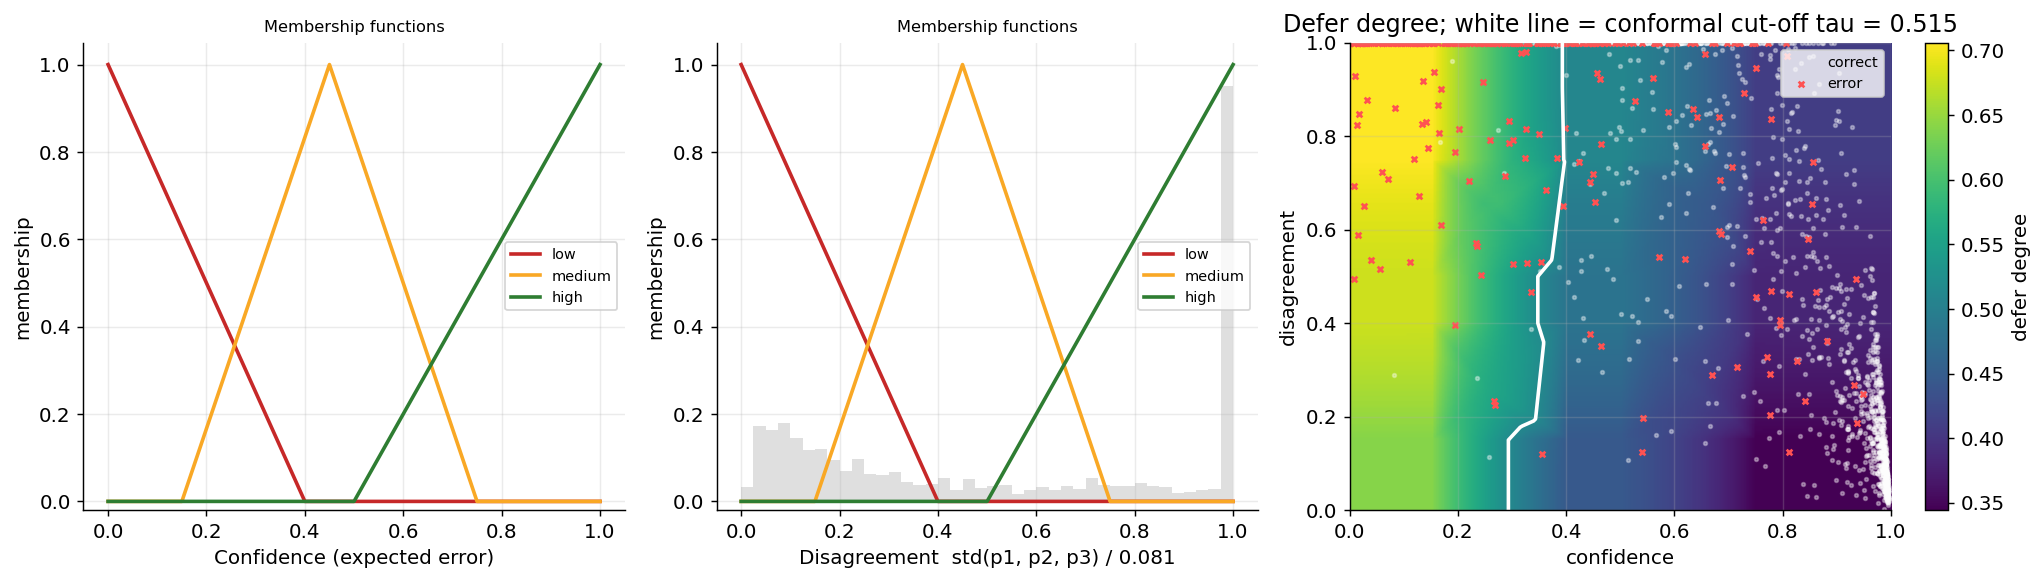

Saved figures/fig13_fuzzy_system.png


In [18]:
evolved = FIS_PARAMS is not HANDSET
conf_te = conf_input(p_te_f, thr_star, FUZZY_CONF)
dis_te = np.clip(X_te.std(1) / FIS_PARAMS["dscale"], 0, 1)
gap = np.abs(fis(conf_te, dis_te, FIS_PARAMS) - fuzzy_defer_degree(p_te_f, X_te, thr_star)).max()
assert gap < 1e-9, f"figure rule base differs from the deployed one ({gap})"

wrong = (p_te_f >= thr_star).astype(int) != L_te
ref = fuzzy_defer_degree(p_te_f, X_te, thr_star) >= TAU
print(f"test errors: {wrong.mean()*100:.1f}% overall | {wrong[ref].mean()*100:.1f}% among referred "
      f"| {wrong[~ref].mean()*100:.1f}% among auto-reported")

g = np.linspace(0, 1, 201)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1, 1, 1.25]})
for a, key, name in [(ax[0], "cmf", f"Confidence ({FUZZY_CONF.replace('_', ' ')})"),
                     (ax[1], "dmf", f"Disagreement  std(p1, p2, p3) / {FIS_PARAMS['dscale']:.3f}")]:
    for t, t0, lab, col in zip(FIS_PARAMS[key], HANDSET[key], ["low", "medium", "high"],
                               ["#C62828", "#F9A825", "#2E7D32"]):
        a.plot(g, trimf(g, *t), lw=2, color=col, label=lab)
    a.set_xlabel(name); a.set_ylabel("membership"); a.set_ylim(-0.02, 1.05); a.legend(fontsize=8)
    a.set_title("Membership functions", fontsize=9)
hc, he = np.histogram(dis_te, bins=40, range=(0, 1))
ax[1].bar(he[:-1], hc / hc.max() * 0.95, width=np.diff(he), align="edge", alpha=0.25, color="gray", label="test cases (scaled)")
CC, DD = np.meshgrid(g, g); SURF = fis(CC, DD, FIS_PARAMS)
im = ax[2].imshow(SURF, origin="lower", extent=[0, 1, 0, 1], aspect="auto", cmap="viridis")
ax[2].contour(CC, DD, SURF, levels=[TAU], colors="white", linewidths=2)
ax[2].scatter(conf_te[~wrong], dis_te[~wrong], s=4, c="white", alpha=0.35, label="correct")
ax[2].scatter(conf_te[wrong], dis_te[wrong], s=10, c="#FF5252", marker="x", label="error")
ax[2].set_xlabel("confidence"); ax[2].set_ylabel("disagreement")
ax[2].set_title(f"Defer degree; white line = conformal cut-off tau = {TAU:.3f}")
ax[2].legend(fontsize=8, loc="upper right"); fig.colorbar(im, ax=ax[2], label="defer degree")
fig.tight_layout(); fig.savefig(FIG_DIR + "fig13_fuzzy_system.png", bbox_inches="tight"); plt.show()
print("Saved figures/fig13_fuzzy_system.png")

## 19. Risk-coverage, bootstrap confidence intervals, DeLong tests

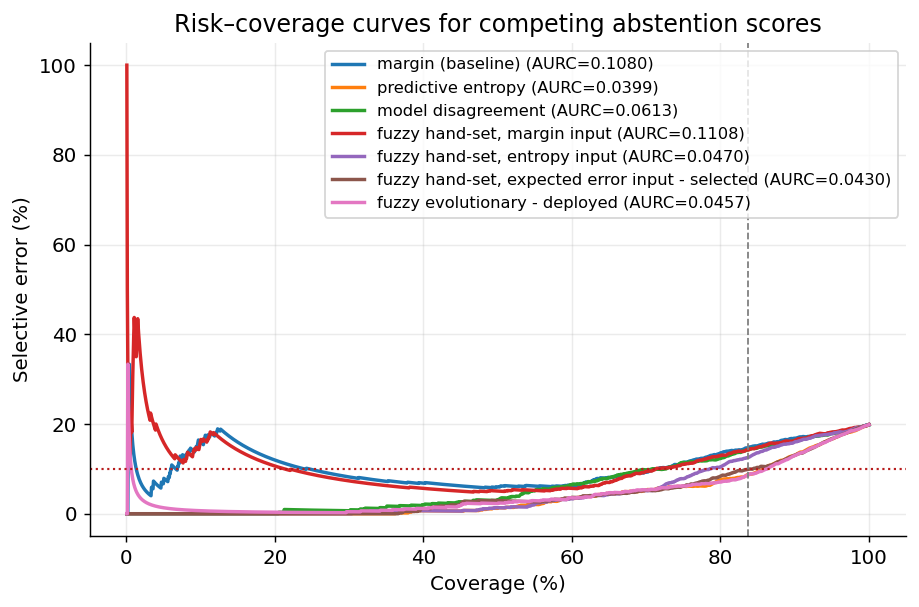

,score,AURC,balanced_risk,risk_at_80_coverage
0,margin (baseline),0.1080,0.0914,0.1354
1,predictive entropy,0.0399,0.0854,0.0748
2,model disagreement,0.0613,0.0995,0.1229
3,"fuzzy hand-set, margin input",0.1108,0.0900,0.1296
4,"fuzzy hand-set, entropy input",0.0470,0.0904,0.1047
5,"fuzzy hand-set, expected error input - selected",0.0430,0.0874,0.0839
6,fuzzy evolutionary - deployed,0.0457,0.0867,0.0706



95% bootstrap CIs (test set):
  AUROC         [0.9159, 0.9448]
  accuracy      [0.7807, 0.8213]
  sensitivity   [0.8694, 0.9387]
  specificity   [0.7530, 0.8007]

DeLong test — fused ensemble vs each backbone:
  vs convnext_tiny    dAUROC=+0.0095  z=+2.72  p=0.0066  (significant)
  vs maxvit_tiny      dAUROC=+0.0205  z=+4.42  p=0.0000  (significant)
  vs swin_tiny        dAUROC=+0.0076  z=+3.19  p=0.0014  (significant)

Saved fig11_reliability.png, fig14_risk_coverage.png, fusion_comparison.csv, aurc_comparison.csv


In [19]:
_trapz = np.trapezoid if hasattr(np, "trapezoid") else np.trapz

def risk_coverage(scores, y, p, thr):
    order = np.argsort(scores)
    yo, po = y[order], p[order]
    wrong = ((po >= thr).astype(int) != yo).astype(float)
    cov = np.arange(1, len(y) + 1) / len(y)
    risk = np.cumsum(wrong) / np.arange(1, len(y) + 1)
    return cov, risk

abst_scores = {
    "margin (baseline)":  -np.abs(p_te_f - thr_star),
    "predictive entropy": -(p_te_f * np.log(p_te_f + 1e-9) + (1 - p_te_f) * np.log(1 - p_te_f + 1e-9)),
    "model disagreement": X_te.std(1),
}
for m in CONF_MODES:
    tag = " - selected" if m == FUZZY_CONF else ""
    abst_scores[f"fuzzy hand-set, {m.replace('_', ' ')} input{tag}"] = fuzzy_defer_degree(p_te_f, X_te, thr_star, m, HANDSET)
abst_scores["fuzzy evolutionary - deployed"] = fuzzy_defer_degree(p_te_f, X_te, thr_star, P=P_EVO)
fig, ax = plt.subplots(figsize=(7.2, 4.8))
aurc_rows = []
for name, s in abst_scores.items():
    cov, risk = risk_coverage(s, L_te, p_te_f, thr_star)
    a = _trapz(risk, cov)
    aurc_rows.append(dict(score=name, AURC=a, balanced_risk=balanced_selective_risk(s, L_te, p_te_f, thr_star),
                          risk_at_80_coverage=risk[int(0.8 * len(cov)) - 1]))
    ax.plot(cov * 100, risk * 100, label=f"{name} (AURC={a:.4f})", linewidth=1.9)
ax.axvline(keep_te.mean() * 100, ls="--", c="gray", lw=1)
ax.axhline(ALPHA * 100, ls=":", c="#B71C1C", lw=1.2)
ax.set_xlabel("Coverage (%)"); ax.set_ylabel("Selective error (%)")
ax.set_title("Risk–coverage curves for competing abstention scores")
ax.legend(fontsize=9); fig.tight_layout()
fig.savefig(FIG_DIR + "fig14_risk_coverage.png", bbox_inches="tight"); plt.show()
display(pd.DataFrame(aurc_rows).round(4))

def boot_ci(fn, n_boot=2000):
    r = np.random.RandomState(SEED)
    vals = [fn(r.randint(0, len(L_te), len(L_te))) for _ in range(n_boot)]
    return np.nanpercentile(vals, 2.5), np.nanpercentile(vals, 97.5)

print("\n95% bootstrap CIs (test set):")
for label, fn in [("AUROC", lambda i: roc_auc_score(L_te[i], p_te_f[i]) if 0 < L_te[i].sum() < len(i) else np.nan),
                  ("accuracy", lambda i: ((p_te_f[i] >= thr_star).astype(int) == L_te[i]).mean()),
                  ("sensitivity", lambda i: metrics_at(L_te[i], p_te_f[i], thr_star)[1]),
                  ("specificity", lambda i: metrics_at(L_te[i], p_te_f[i], thr_star)[2])]:
    lo, hi = boot_ci(fn)
    print(f"  {label:14}[{lo:.4f}, {hi:.4f}]")

def _midrank(x):
    J = np.argsort(x); Z = x[J]; N = len(x); Tr = np.zeros(N); i = 0
    while i < N:
        j = i
        while j < N and Z[j] == Z[i]:
            j += 1
        Tr[i:j] = 0.5 * (i + j - 1) + 1
        i = j
    out = np.empty(N); out[J] = Tr
    return out

def delong(y, p1, p2):
    m, n = int((y == 1).sum()), int((y == 0).sum())
    preds = np.vstack([p1, p2])
    V01 = np.zeros((2, m)); V10 = np.zeros((2, n)); A = np.zeros(2)
    for r in range(2):
        P, N_ = preds[r][y == 1], preds[r][y == 0]
        tz = _midrank(np.r_[P, N_]); tx = _midrank(P); ty = _midrank(N_)
        A[r] = (tz[:m].sum() - m * (m + 1) / 2) / (m * n)
        V01[r] = (tz[:m] - tx) / n
        V10[r] = 1.0 - (tz[m:] - ty) / m
    S = np.cov(V01) / m + np.cov(V10) / n
    d = np.array([1.0, -1.0])
    z = (A[0] - A[1]) / np.sqrt(max(d @ S @ d, 1e-12))
    return A, 2 * (1 - norm.cdf(abs(z))), z

print("\nDeLong test — fused ensemble vs each backbone:")
for k in model_names:
    A, pv, z = delong(L_te, p_te_f, per_te[k])
    print(f"  vs {k:16} dAUROC={A[0]-A[1]:+.4f}  z={z:+.2f}  p={pv:.4f}  "
          f"({'significant' if pv < 0.05 else 'NOT significant'})")

pd.DataFrame(aurc_rows).to_csv(SAVE_DIR + "aurc_comparison.csv", index=False)
print("\nSaved fig11_reliability.png, fig14_risk_coverage.png, fusion_comparison.csv, aurc_comparison.csv")

## 20. Coverage sweep

,target_coverage,tau,test_coverage,n_predicted,n_deferred,selective_acc,sens,spec,deferred_malignant_rate
0,1.00,NaN,1.0000,1505,0,0.8013,0.9062,0.7765,NaN
1,0.95,0.7060,0.9528,1434,71,0.8312,0.9015,0.8147,0.1972
2,0.90,0.6315,0.9090,1368,137,0.8640,0.8977,0.8560,0.1752
3,0.85,0.5345,0.8525,1283,222,0.9057,0.8893,0.9095,0.1982
4,0.80,0.5110,0.8106,1220,285,0.9270,0.9144,0.9299,0.2316
5,0.75,0.5029,0.7561,1138,367,0.9376,0.9183,0.9419,0.2180
6,0.70,0.4865,0.7209,1085,420,0.9419,0.9158,0.9475,0.2333
7,0.60,0.4357,0.6299,948,557,0.9578,0.9103,0.9664,0.2567
8,0.50,0.4010,0.5309,799,706,0.9725,0.9143,0.9813,0.2592



Conformal operating point (alpha=0.1, delta=0.05): coverage 83.7% (1260/1505 answered), selective accuracy 91.27%, sens 88.5%, spec 91.9%
Referred cases: 21.6% malignant (base rate 19.1%), error rate 77.1% vs 8.7% among answered.


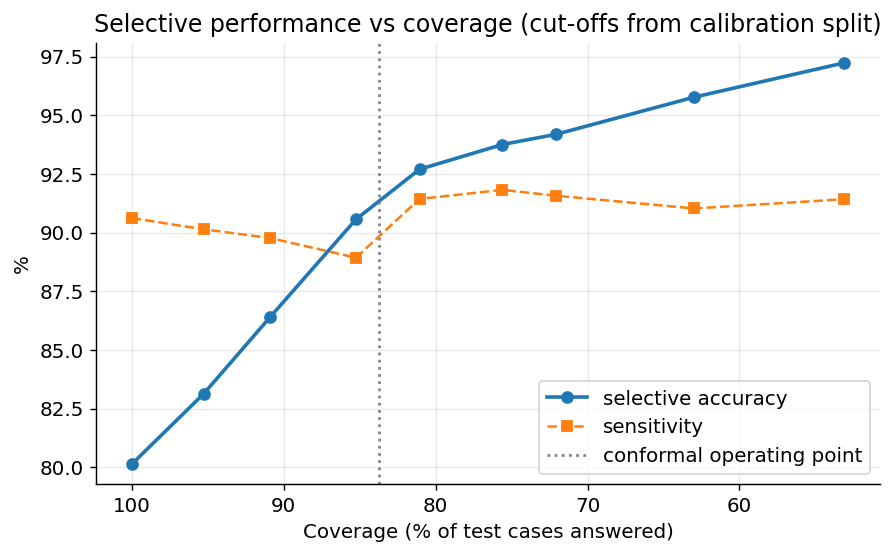

In [20]:
fz_cal = fuzzy_defer_degree(p_va_f[CAL_IDX], X_va[CAL_IDX], thr_star)
fz_tst = fuzzy_defer_degree(p_te_f, X_te, thr_star)
yc, pc = L_va[CAL_IDX], p_va_f[CAL_IDX]

def sel_stats(keep, y, p, t):
    n = int(keep.sum())
    if n == 0:
        return dict(n_pred=0, acc=np.nan, sens=np.nan, spec=np.nan)
    pred = (p[keep] >= t).astype(int); yy = y[keep]
    tp = int(((pred == 1) & (yy == 1)).sum()); tn = int(((pred == 0) & (yy == 0)).sum())
    fp = int(((pred == 1) & (yy == 0)).sum()); fn = int(((pred == 0) & (yy == 1)).sum())
    return dict(n_pred=n, acc=(tp + tn) / n,
                sens=tp / (tp + fn) if (tp + fn) else np.nan,
                spec=tn / (tn + fp) if (tn + fp) else np.nan)

rows = []
for target in [1.00, 0.95, 0.90, 0.85, 0.80, 0.75, 0.70, 0.60, 0.50]:
    tau = np.inf if target >= 1.0 else float(np.quantile(fz_cal, target))
    keep = fz_tst <= tau if np.isfinite(tau) else np.ones(len(L_te), bool)
    s = sel_stats(keep, L_te, p_te_f, thr_star)
    rows.append(dict(target_coverage=target, tau=round(tau, 4) if np.isfinite(tau) else None,
                     test_coverage=keep.mean(), n_predicted=s["n_pred"],
                     n_deferred=int((~keep).sum()),
                     selective_acc=s["acc"], sens=s["sens"], spec=s["spec"],
                     deferred_malignant_rate=L_te[~keep].mean() if (~keep).any() else np.nan))

sweep = pd.DataFrame(rows)
display(sweep.round(4))
sweep.to_csv(SAVE_DIR + "coverage_sweep.csv", index=False)

APP_TAU = TAU
keep_app = fz_tst < APP_TAU
s_app = sel_stats(keep_app, L_te, p_te_f, thr_star)
print(f"\nConformal operating point (alpha={ALPHA}, delta={DELTA}): "
      f"coverage {keep_app.mean()*100:.1f}% ({s_app['n_pred']}/{len(L_te)} answered), "
      f"selective accuracy {s_app['acc']*100:.2f}%, sens {s_app['sens']*100:.1f}%, "
      f"spec {s_app['spec']*100:.1f}%")
_wr = (p_te_f >= thr_star).astype(int) != L_te
print(f"Referred cases: {L_te[~keep_app].mean()*100:.1f}% malignant (base rate {L_te.mean()*100:.1f}%), "
      f"error rate {_wr[~keep_app].mean()*100:.1f}% vs {_wr[keep_app].mean()*100:.1f}% among answered.")

fig, ax = plt.subplots(figsize=(7, 4.4))
ax.plot(sweep.test_coverage * 100, sweep.selective_acc * 100, "o-", lw=2, label="selective accuracy")
ax.plot(sweep.test_coverage * 100, sweep.sens * 100, "s--", lw=1.4, label="sensitivity")
ax.axvline(keep_app.mean() * 100, ls=":", c="gray", label="conformal operating point")
ax.set_xlabel("Coverage (% of test cases answered)"); ax.set_ylabel("%")
ax.set_title("Selective performance vs coverage (cut-offs from calibration split)")
ax.invert_xaxis(); ax.legend(); fig.tight_layout()
fig.savefig(FIG_DIR + "fig15_coverage_sweep.png", bbox_inches="tight"); plt.show()

## 21. Operating points

In [21]:
def _m(y, p, t):
    pred = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    se = tp / (tp + fn) if (tp + fn) else 0.0
    sp = tn / (tn + fp) if (tn + fp) else 0.0
    ppv = tp / (tp + fp) if (tp + fp) else 0.0
    npv = tn / (tn + fn) if (tn + fn) else 0.0
    return dict(acc=(tp + tn) / len(y), sens=se, spec=sp, bal=(se + sp) / 2, ppv=ppv, npv=npv)

grid = np.linspace(0.02, 0.98, 241)
t_acc = max(grid, key=lambda t: _m(L_va, ens_va, t)["acc"])
t_bal = max(grid, key=lambda t: _m(L_va, ens_va, t)["bal"])
feas = [t for t in grid if _m(L_va, ens_va, t)["sens"] >= 0.90]
t_sens = max(feas, key=lambda t: _m(L_va, ens_va, t)["bal"]) if feas else t_bal

rows = []
for name, t in [("accuracy-optimal", t_acc), ("balanced-accuracy", t_bal),
                ("sensitivity floor 0.90", t_sens)]:
    m = _m(L_te, ens_te, t); m["operating_point"] = name; m["thr"] = round(float(t), 3)
    rows.append(m)
op = pd.DataFrame(rows)[["operating_point", "thr", "acc", "sens", "spec", "bal", "ppv", "npv"]]
display(op.round(4))
op.to_csv(SAVE_DIR + "operating_points.csv", index=False)

base = 1 - L_te.mean()
print(f"\nTest AUROC {roc_auc_score(L_te, ens_te):.4f} (threshold-free)")
print(f"Majority-class baseline accuracy: {base*100:.2f}%")

print("\nPPV at the sensitivity-floor point across plausible prevalences:")
mm = _m(L_te, ens_te, t_sens)
for prev in [0.01, 0.02, 0.05, 0.10, float(L_te.mean())]:
    ppv = (mm["sens"] * prev) / (mm["sens"] * prev + (1 - mm["spec"]) * (1 - prev) + 1e-12)
    tag = " (this test set)" if abs(prev - L_te.mean()) < 1e-9 else ""
    print(f"  prevalence {prev*100:5.1f}%  ->  PPV {ppv*100:5.1f}%{tag}")

,operating_point,thr,acc,sens,spec,bal,ppv,npv
0,accuracy-optimal,0.628,0.8910,0.6771,0.9417,0.8094,0.7331,0.9249
1,balanced-accuracy,0.424,0.8372,0.8611,0.8316,0.8463,0.5475,0.9620
2,sensitivity floor 0.90,0.424,0.8372,0.8611,0.8316,0.8463,0.5475,0.9620



Test AUROC 0.9273 (threshold-free)
Majority-class baseline accuracy: 80.86%

PPV at the sensitivity-floor point across plausible prevalences:
  prevalence   1.0%  ->  PPV   4.9%
  prevalence   2.0%  ->  PPV   9.4%
  prevalence   5.0%  ->  PPV  21.2%
  prevalence  10.0%  ->  PPV  36.2%
  prevalence  19.1%  ->  PPV  54.7% (this test set)


## 22. External validation on PH2

PH2 images: /kaggle/input/datasets/spacesurfer/ph2-dataset/PH2Dataset/PH2 Dataset images
200 dermoscopic images found (expected 200)
PH2 labels: {'common': 80, 'atypical': 80, 'melanoma': 40} | 200 images
PH2 verified: 200 images, 40 melanoma (20.0% malignant)


  convnext_tiny    PH2 AUROC 0.9269
  maxvit_tiny      PH2 AUROC 0.9119
  swin_tiny        PH2 AUROC 0.9223


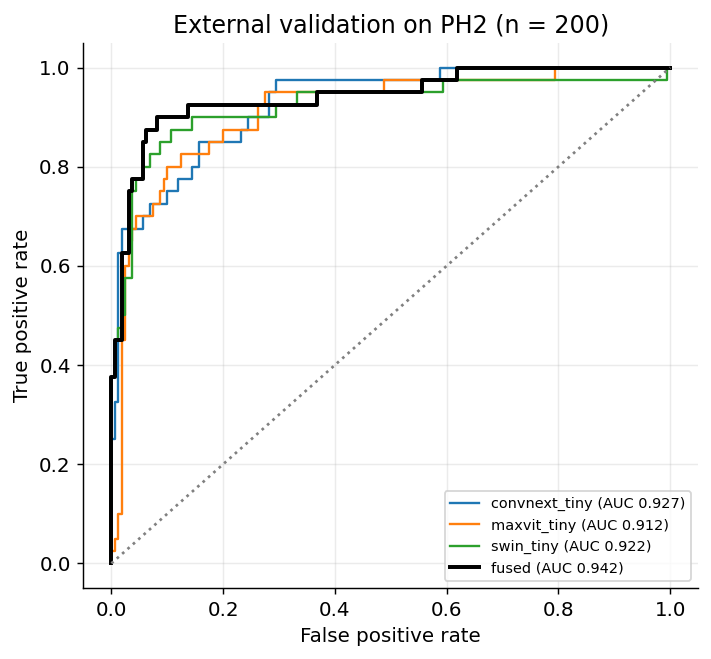


PH2 external (DE-weighted, threshold 0.380 from HAM validation):
  AUROC 0.9416 | acc 0.9250 | sens 0.7500 | spec 0.9688 | bal 0.8594
  AUROC 95% CI [0.8925, 0.9799]
  triage on PH2: 94.0% answered (188/200), selective accuracy 93.09%, 12 referred
  re-tuned on PH2 (upper bound only): bal acc 0.9094

PH2 contains only nevi and melanoma - no BCC or AKIEC - so this is a
narrower task than the HAM10000 definition used for training.


In [22]:
import re
PH2_ROOT = "/kaggle/input/datasets/spacesurfer/ph2-dataset/PH2Dataset"
PH2_IMG_DIR = PH2_ROOT + "/PH2 Dataset images"
if not os.path.isdir(PH2_IMG_DIR):
    hits = glob.glob("/kaggle/input/**/PH2 Dataset images", recursive=True)
    PH2_IMG_DIR = hits[0] if hits else None
    PH2_ROOT = os.path.dirname(PH2_IMG_DIR) if PH2_IMG_DIR else None

if PH2_IMG_DIR is None:
    print("PH2 not found under /kaggle/input - skipping external validation.")
else:
    print("PH2 images:", PH2_IMG_DIR)
    name2path = {os.path.splitext(os.path.basename(p))[0]: p
                 for p in glob.glob(PH2_IMG_DIR + "/*/*_Dermoscopic_Image/*.bmp")}
    print(f"{len(name2path)} dermoscopic images found (expected 200)")

    def _norm(v):
        return "" if (v is None or (isinstance(v, float) and np.isnan(v))) else str(v).strip()

    rows_ = []
    xlsx = PH2_ROOT + "/PH2_dataset.xlsx"
    if os.path.exists(xlsx):
        try:
            x = pd.read_excel(xlsx, sheet_name=0, header=None)
            col = None
            for _, r in x.iterrows():
                vals = [_norm(v).lower() for v in r.values]
                if {"common nevus", "atypical nevus", "melanoma"} <= set(vals):
                    col = {k: vals.index(k) for k in ("common nevus", "atypical nevus", "melanoma")}
                    break
            if col is None:
                print("xlsx: diagnosis header row not found")
            else:
                short = {"common nevus": "common", "atypical nevus": "atypical", "melanoma": "melanoma"}
                for _, r in x.iterrows():
                    vals = [_norm(v) for v in r.values]
                    name = next((v for v in vals if re.fullmatch(r"IMD\d+", v)), None)
                    if name is None or name not in name2path:
                        continue
                    marked = [k for k, c in col.items() if c < len(vals) and vals[c].upper() == "X"]
                    if len(marked) != 1:
                        continue
                    cls = short[marked[0]]
                    rows_.append(dict(image_name=name, path=name2path[name],
                                      target=int(cls == "melanoma"), cls=cls))
        except Exception as e:
            print("xlsx read failed:", e)

    txt = PH2_ROOT + "/PH2_dataset.txt"
    if not rows_ and os.path.exists(txt):
        lines = open(txt, encoding="utf-8", errors="ignore").read().splitlines()
        hdr = next((l for l in lines if "clinical diagnosis" in l.lower()), None)
        if hdr:
            ci = next(k for k, t in enumerate(hdr.split("||")) if "clinical diagnosis" in t.lower())
            for l in lines:
                t = [v.strip() for v in l.split("||")]
                name = next((v for v in t if re.fullmatch(r"IMD\d+", v)), None)
                if name in name2path and ci < len(t) and t[ci] in ("0", "1", "2"):
                    cls = {"0": "common", "1": "atypical", "2": "melanoma"}[t[ci]]
                    rows_.append(dict(image_name=name, path=name2path[name],
                                      target=int(cls == "melanoma"), cls=cls))

    lab = (pd.DataFrame(rows_).drop_duplicates("image_name").reset_index(drop=True)
           if rows_ else pd.DataFrame(columns=["image_name", "path", "target", "cls"]))
    counts = lab.cls.value_counts().to_dict()
    print("PH2 labels:", counts, f"| {len(lab)} images")
    if len(lab) != 200 or counts.get("melanoma", 0) != 40:
        print("PH2 labels do not match the published 80 / 80 / 40 split - external validation skipped.")
        if os.path.exists(xlsx):
            print(pd.read_excel(xlsx, sheet_name=0, header=None).head(15).to_string())
    else:
        print(f"PH2 verified: 200 images, 40 melanoma ({lab.target.mean()*100:.1f}% malignant)")

        class ExternalDS(Dataset):
            def __init__(self, df, tfm): self.df = df.reset_index(drop=True); self.tfm = tfm
            def __len__(self): return len(self.df)
            def __getitem__(self, i):
                r = self.df.iloc[i]
                return self.tfm(Image.open(r["path"]).convert("RGB")), int(r["target"])

        dl = DataLoader(ExternalDS(lab, eval_tfm), batch_size=BATCH_SIZE * 2,
                        shuffle=False, num_workers=2)
        per_ext, y_ext = per_model_probs(dl)
        X_ext = np.stack([per_ext[k] for k in model_names], 1)
        for j, k in enumerate(model_names):
            print(f"  {k:<16} PH2 AUROC {roc_auc_score(y_ext, X_ext[:, j]):.4f}")

        def fuse_probs(X):
            if BEST_FUSION == "DE-weighted":      return X @ W_DE
            if BEST_FUSION == "Choquet (Sugeno)": return choquet(X, g_dens, LAM)
            if BEST_FUSION == "stacking (LR)":    return meta_tune.predict_proba(X)[:, 1]
            return X.mean(1)

        ens_ext = fuse_probs(X_ext)
        auc_ext = roc_auc_score(y_ext, ens_ext)
        fig, ax = plt.subplots(figsize=(5.6, 5.2))
        for j, k in enumerate(model_names):
            fpr, tpr, _ = roc_curve(y_ext, X_ext[:, j])
            ax.plot(fpr, tpr, lw=1.3, label=f"{k} (AUC {roc_auc_score(y_ext, X_ext[:, j]):.3f})")
        fpr, tpr, _ = roc_curve(y_ext, ens_ext)
        ax.plot(fpr, tpr, "k", lw=2.2, label=f"fused (AUC {auc_ext:.3f})")
        ax.plot([0, 1], [0, 1], ":", c="gray")
        ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
        ax.set_title(f"External validation on PH2 (n = {len(y_ext)})")
        ax.legend(fontsize=8, loc="lower right"); fig.tight_layout()
        fig.savefig(FIG_DIR + "fig16_ph2_roc.png", bbox_inches="tight"); plt.show()
        me = _m(y_ext, ens_ext, thr_star)
        print(f"\nPH2 external ({BEST_FUSION}, threshold {thr_star:.3f} from HAM validation):")
        print(f"  AUROC {auc_ext:.4f} | acc {me['acc']:.4f} | sens {me['sens']:.4f} | "
              f"spec {me['spec']:.4f} | bal {me['bal']:.4f}")

        rng = np.random.RandomState(SEED); b = []
        for _ in range(2000):
            i_ = rng.randint(0, len(y_ext), len(y_ext))
            if 0 < y_ext[i_].sum() < len(i_):
                b.append(roc_auc_score(y_ext[i_], ens_ext[i_]))
        lo, hi = np.percentile(b, 2.5), np.percentile(b, 97.5)
        print(f"  AUROC 95% CI [{lo:.4f}, {hi:.4f}]")

        fz_ext = fuzzy_defer_degree(ens_ext, X_ext, thr_star)
        keep_ext = fz_ext < TAU
        if keep_ext.any():
            pe = (ens_ext[keep_ext] >= thr_star).astype(int)
            sel_acc_ext = float((pe == y_ext[keep_ext]).mean())
            print(f"  triage on PH2: {keep_ext.mean()*100:.1f}% answered "
                  f"({int(keep_ext.sum())}/{len(y_ext)}), selective accuracy {sel_acc_ext*100:.2f}%, "
                  f"{int((~keep_ext).sum())} referred")
        else:
            sel_acc_ext = float("nan")
            print("  triage on PH2: all cases referred")

        t_ext = max(np.linspace(0.02, 0.98, 241), key=lambda t: _m(y_ext, ens_ext, t)["bal"])
        print(f"  re-tuned on PH2 (upper bound only): bal acc {_m(y_ext, ens_ext, t_ext)['bal']:.4f}")
        print("\nPH2 contains only nevi and melanoma - no BCC or AKIEC - so this is a")
        print("narrower task than the HAM10000 definition used for training.")

        json.dump(dict(ph2_n=int(len(y_ext)), ph2_auroc=float(auc_ext),
                       ph2_auroc_ci=[float(lo), float(hi)], ph2_acc=float(me["acc"]),
                       ph2_sens=float(me["sens"]), ph2_spec=float(me["spec"]),
                       ph2_bal=float(me["bal"]),
                       ph2_coverage=float(keep_ext.mean()), ph2_selective_acc=sel_acc_ext),
                  open(SAVE_DIR + "ph2_external.json", "w"), indent=2)

## 23. Figure: system pipeline

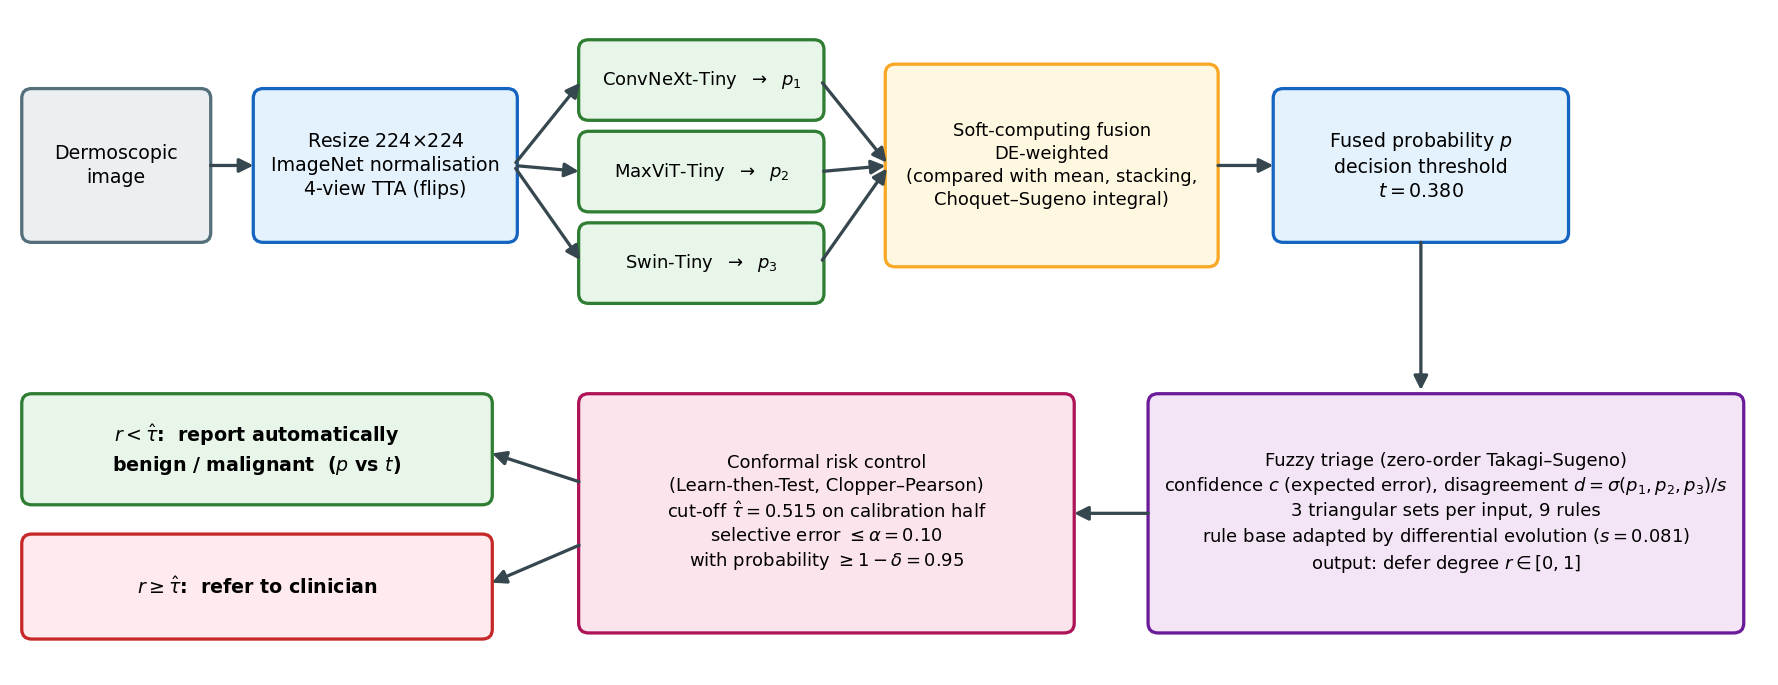

Saved figures/fig01_pipeline.png


In [23]:
from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(14, 5.4)); ax.set_xlim(0, 14); ax.set_ylim(0, 5.4); ax.axis("off")
def box(x, y, w, h, txt, fc, ec, fs=10.5, bold=False):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.03,rounding_size=0.08", fc=fc, ec=ec, lw=1.8))
    ax.text(x + w / 2, y + h / 2, txt, ha="center", va="center", fontsize=fs,
            fontweight="bold" if bold else "normal", linespacing=1.35)
def arrow(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="-|>", lw=1.8, color="#37474F", mutation_scale=16))
names = {"convnext_tiny": "ConvNeXt-Tiny", "maxvit_tiny": "MaxViT-Tiny", "swin_tiny": "Swin-Tiny"}
router = "adapted by differential evolution" if deploy_cfg.get("fuzzy_router") == "fuzzy, evolutionary" else "hand-set"
box(0.1, 3.55, 1.45, 1.2, "Dermoscopic\nimage", "#ECEFF1", "#546E7A")
box(1.95, 3.55, 2.05, 1.2, f"Resize {IMG_SIZE}$\\times${IMG_SIZE}\nImageNet normalisation\n4-view TTA (flips)", "#E3F2FD", "#1565C0")
for k, m in enumerate(model_names):
    box(4.55, 4.55 - k * 0.75, 1.9, 0.6, f"{names.get(m, m)}  $\\rightarrow$  $p_{k + 1}$", "#E8F5E9", "#2E7D32", fs=10)
    arrow(4.0, 4.15, 4.55, 4.85 - k * 0.75); arrow(6.45, 4.85 - k * 0.75, 7.0, 4.15)
box(7.0, 3.35, 2.6, 1.6, f"Soft-computing fusion\n{BEST_FUSION}\n(compared with mean, stacking,\nChoquet–Sugeno integral)", "#FFF8E1", "#F9A825", fs=10)
box(10.1, 3.55, 2.3, 1.2, f"Fused probability $p$\ndecision threshold\n$t = {thr_star:.3f}$", "#E3F2FD", "#1565C0")
arrow(1.55, 4.15, 1.95, 4.15); arrow(9.6, 4.15, 10.1, 4.15)
box(9.1, 0.35, 4.7, 1.9, "Fuzzy triage (zero-order Takagi–Sugeno)\n"
    f"confidence $c$ ({FUZZY_CONF.replace('_', ' ')}), disagreement $d=\\sigma(p_1,p_2,p_3)/s$\n"
    f"3 triangular sets per input, 9 rules\nrule base {router} ($s = {FIS_PARAMS['dscale']:.3f}$)\n"
    "output: defer degree $r\\in[0,1]$", "#F3E5F5", "#6A1B9A", fs=10)
box(4.55, 0.35, 3.9, 1.9, "Conformal risk control\n(Learn-then-Test, Clopper–Pearson)\n"
    f"cut-off $\\hat{{\\tau}} = {TAU:.3f}$ on calibration half\n"
    f"selective error $\\leq \\alpha = {ALPHA:.2f}$\nwith probability $\\geq 1-\\delta = {1 - DELTA:.2f}$", "#FCE4EC", "#AD1457", fs=10)
box(0.1, 1.4, 3.7, 0.85, "$r < \\hat{\\tau}$:  report automatically\nbenign / malignant  ($p$ vs $t$)", "#E8F5E9", "#2E7D32", bold=True)
box(0.1, 0.3, 3.7, 0.8, "$r \\geq \\hat{\\tau}$:  refer to clinician", "#FFEBEE", "#C62828", bold=True)
arrow(11.25, 3.55, 11.25, 2.28); arrow(9.1, 1.3, 8.45, 1.3); arrow(4.55, 1.55, 3.8, 1.8); arrow(4.55, 1.05, 3.8, 0.72)
fig.tight_layout(); fig.savefig(FIG_DIR + "fig01_pipeline.png", bbox_inches="tight", facecolor="white"); plt.show()
print("Saved figures/fig01_pipeline.png")

## 24. Results summary

In [24]:
import shutil
summary = {
    "test_n": int(len(L_te)),
    "test_malignant_rate": round(float(L_te.mean()), 4),
    "majority_baseline_acc": round(float(1 - L_te.mean()), 4),
    "ensemble_auroc": round(float(roc_auc_score(L_te, ens_te)), 4),
    "combiner": combiner if "combiner" in dir() else None,
    "triage_fusion": BEST_FUSION, "fuzzy_confidence_input": FUZZY_CONF,
    "fuzzy_router": deploy_cfg.get("fuzzy_router"), "triage_tau": round(float(TAU), 4),
    "triage_coverage": round(float(keep_te.mean()), 4),
}
for k in model_names:
    summary[f"auroc_{k}"] = round(float(roc_auc_score(L_te, per_te[k])), 4)

if "op" in dir():
    for _, r in op.iterrows():
        tag = r.operating_point.replace(" ", "_").replace(".", "")
        summary[f"{tag}_acc"] = round(float(r.acc), 4)
        summary[f"{tag}_sens"] = round(float(r.sens), 4)
        summary[f"{tag}_spec"] = round(float(r.spec), 4)

for f, keys in [("ph2_external.json", None),
                ("fusion_comparison.csv", None),
                ("aurc_comparison.csv", None),
                ("coverage_sweep.csv", None),
                ("router_comparison.csv", None)]:
    p = SAVE_DIR + f
    summary[f.split("/")[-1]] = "present" if os.path.exists(p) else "not run"

shutil.make_archive(SAVE_DIR + "paper_figures", "zip", FIG_DIR)
print(json.dumps(summary, indent=2))
json.dump(summary, open(SAVE_DIR + "paper_summary.json", "w"), indent=2)

print("\nArtifacts in", SAVE_DIR)
for p in sorted(glob.glob(SAVE_DIR + "*.csv") + glob.glob(SAVE_DIR + "*.json")
                + glob.glob(SAVE_DIR + "leakage_audit/*.csv")):
    print("  ", p.replace(SAVE_DIR, ""))

print("""
Where each result is produced:
  calibration and fuzzy conformal triage  -> sections 13-18
  coverage sweep (selective accuracy)     -> section 20
  operating points                        -> section 21
  external validation on PH2              -> section 22
  backend bundle exported + self-tested   -> section 25
  leakage audit (3 seeds, protocols A-D)  -> Part B, sections 26-31
Report AUROC as the primary metric; accuracy alongside the majority baseline.""")

{
  "test_n": 1505,
  "test_malignant_rate": 0.1914,
  "majority_baseline_acc": 0.8086,
  "ensemble_auroc": 0.9273,
  "combiner": "top2",
  "triage_fusion": "DE-weighted",
  "fuzzy_confidence_input": "expected_error",
  "fuzzy_router": "fuzzy, evolutionary",
  "triage_tau": 0.515,
  "triage_coverage": 0.8372,
  "auroc_convnext_tiny": 0.9212,
  "auroc_maxvit_tiny": 0.9103,
  "auroc_swin_tiny": 0.9232,
  "accuracy-optimal_acc": 0.891,
  "accuracy-optimal_sens": 0.6771,
  "accuracy-optimal_spec": 0.9417,
  "balanced-accuracy_acc": 0.8372,
  "balanced-accuracy_sens": 0.8611,
  "balanced-accuracy_spec": 0.8316,
  "sensitivity_floor_090_acc": 0.8372,
  "sensitivity_floor_090_sens": 0.8611,
  "sensitivity_floor_090_spec": 0.8316,
  "ph2_external.json": "present",
  "fusion_comparison.csv": "present",
  "aurc_comparison.csv": "present",
  "coverage_sweep.csv": "present",
  "router_comparison.csv": "present"
}

Artifacts in /kaggle/working/
   aurc_comparison.csv
   coverage_sweep.csv
   deploy

## 25. Backend export and self-test

In [25]:
import shutil, importlib.util

BK = SAVE_DIR + "backend/"
os.makedirs(BK, exist_ok=True)
for k in MODELS:
    shutil.copy(SAVE_DIR + f"model_{k}.pth", BK + f"model_{k}.pth")

cfg = dict(
    models=dict(MODELS), img_size=IMG_SIZE,
    mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225], tta=bool(USE_TTA),
    fusion=BEST_FUSION,
    de_weights=[float(w) for w in W_DE],
    sugeno_densities=[float(g) for g in g_dens], sugeno_lambda=float(LAM),
    stacking_coef=[float(c) for c in meta_tune.coef_.ravel()],
    stacking_intercept=float(meta_tune.intercept_[0]),
    model_order=list(model_names),
    threshold=float(thr_star), fuzzy_conf=FUZZY_CONF,
    fis_params=FIS_PARAMS,
    defer_tau=float(TAU),
    conformal_tau=float(TAU), alpha=float(ALPHA), delta=float(DELTA),
)
json.dump(cfg, open(BK + "deploy_config.json", "w"), indent=2)

INFERENCE_SRC = """# inference.py - skin lesion triage (benign / malignant / refer)
import json, os
import numpy as np, torch, torch.nn as nn, timm
from PIL import Image
import torchvision.transforms as T

class SkinModel(nn.Module):
    def __init__(self, name):
        super().__init__()
        self.backbone = timm.create_model(name, pretrained=False, num_classes=0)
        self.head = nn.Sequential(nn.Dropout(0.5), nn.Linear(self.backbone.num_features, 2))
    def forward(self, x):
        return self.head(self.backbone(x))

def _trimf(x, a, b, c):
    return np.clip(np.minimum((x - a) / (b - a + 1e-9), (c - x) / (c - b + 1e-9)), 0, 1)

def conf_input(p, thr, mode):
    if mode == "entropy":
        pc = np.clip(p, 1e-6, 1 - 1e-6)
        return np.clip(1 + (pc * np.log(pc) + (1 - pc) * np.log(1 - pc)) / np.log(2), 0, 1)
    if mode == "expected_error":
        e = np.where(p >= thr, 1 - p, p)
        return np.clip(1 - e / max(thr, 1 - thr), 0, 1)
    return np.clip(np.abs(p - thr) / max(thr, 1 - thr), 0, 1)

def fis(conf, dis, P):
    c = [_trimf(conf, *t) for t in P["cmf"]]; d = [_trimf(dis, *t) for t in P["dmf"]]
    num, den = 0.0, 0.0
    for i in range(3):
        for j in range(3):
            w = np.minimum(c[i], d[j]); num = num + w * P["Z"][i][j]; den = den + w
    return num / (den + 1e-9)

def defer_degree(p, X, thr, mode, P):
    return fis(conf_input(p, thr, mode), np.clip(X.std(1) / P["dscale"], 0, 1), P)

def _choquet(X, g, lam):
    idx = np.argsort(X, axis=1)
    Xs = np.take_along_axis(X, idx, axis=1); gs = g[idx]
    out = np.zeros(len(X)); prev = np.zeros(len(X))
    for i in range(X.shape[1]):
        tail = gs[:, i:]
        mu = tail.sum(1) if abs(lam) < 1e-8 else (np.prod(1 + lam * tail, axis=1) - 1) / lam
        out += (Xs[:, i] - prev) * np.clip(mu, 0, 1); prev = Xs[:, i]
    return np.clip(out, 0, 1)

class Triage:
    def __init__(self, folder, device=None):
        self.cfg = json.load(open(os.path.join(folder, "deploy_config.json")))
        self.dev = device or ("cuda" if torch.cuda.is_available() else "cpu")
        self.order = self.cfg["model_order"]
        self.models = {}
        for k in self.order:
            m = SkinModel(self.cfg["models"][k])
            m.load_state_dict(torch.load(os.path.join(folder, "model_" + k + ".pth"), map_location=self.dev))
            self.models[k] = m.to(self.dev).eval()
        s = self.cfg["img_size"]
        self.tfm = T.Compose([T.Resize((s, s)), T.ToTensor(), T.Normalize(self.cfg["mean"], self.cfg["std"])])

    @torch.no_grad()
    def model_probs(self, imgs):
        x = torch.stack([self.tfm(im.convert("RGB")) for im in imgs]).to(self.dev)
        views = [x] + ([torch.flip(x, [3]), torch.flip(x, [2]), torch.flip(x, [2, 3])] if self.cfg["tta"] else [])
        cols = []
        for k in self.order:
            ps = [torch.softmax(self.models[k](v), 1)[:, 1] for v in views]
            cols.append(torch.stack(ps, 0).mean(0).cpu().numpy())
        return np.stack(cols, 1)

    def fuse(self, X):
        f = self.cfg["fusion"]
        if f == "DE-weighted":
            return X @ np.array(self.cfg["de_weights"])
        if f == "Choquet (Sugeno)":
            return _choquet(X, np.array(self.cfg["sugeno_densities"]), self.cfg["sugeno_lambda"])
        if f == "stacking (LR)":
            z = X @ np.array(self.cfg["stacking_coef"]) + self.cfg["stacking_intercept"]
            return 1 / (1 + np.exp(-z))
        return X.mean(1)

    def predict(self, imgs):
        if not isinstance(imgs, (list, tuple)):
            imgs = [imgs]
        X = self.model_probs(imgs)
        p = self.fuse(X)
        thr = self.cfg["threshold"]
        dd = defer_degree(p, X, thr, self.cfg["fuzzy_conf"], self.cfg["fis_params"])
        out = []
        for i in range(len(p)):
            refer = bool(dd[i] >= self.cfg["defer_tau"])
            out.append(dict(
                decision="refer" if refer else ("malignant" if p[i] >= thr else "benign"),
                malignancy_prob=round(float(p[i]), 4),
                defer_degree=round(float(dd[i]), 4),
                model_probs={k: round(float(X[i, j]), 4) for j, k in enumerate(self.order)},
                model_disagreement=round(float(X[i].std()), 4)))
        return out
"""
open(BK + "inference.py", "w").write(INFERENCE_SRC)
open(BK + "requirements.txt", "w").write("torch\ntorchvision\ntimm\nnumpy\npillow\n")

spec = importlib.util.spec_from_file_location("inference", BK + "inference.py")
inf = importlib.util.module_from_spec(spec); spec.loader.exec_module(inf)
tri = inf.Triage(BK, device=DEVICE)

te_df = pd.read_csv(SPLITS_DIR + "ham_test.csv")
n = min(24, len(te_df))
imgs = [Image.open(HAM_LOOKUP[nm]) for nm in te_df.image_name.iloc[:n]]
res = tri.predict(imgs)
p_exp = np.array([r["malignancy_prob"] for r in res])
d_exp = np.array([r["defer_degree"] for r in res])
dp = np.abs(p_exp - p_te_f[:n]).max()
dd = np.abs(d_exp - fuzzy_defer_degree(p_te_f[:n], X_te[:n], thr_star)).max()
print(f"self-test on {n} test images: max |prob diff| {dp:.5f} | max |defer diff| {dd:.5f}")
print("PASS - backend reproduces notebook" if dp < 1e-3 and dd < 1e-3
      else "MISMATCH - check fusion/TTA settings before deploying")
print("\nexample output:", json.dumps(res[0], indent=2))

shutil.make_archive(SAVE_DIR + "backend_bundle", "zip", BK)
print("\nbackend_bundle.zip ->", SAVE_DIR + "backend_bundle.zip")
print("Usage:  from inference import Triage;  Triage('backend').predict(PIL_image)")

self-test on 24 test images: max |prob diff| 0.00005 | max |defer diff| 0.00005
PASS - backend reproduces notebook

example output: {
  "decision": "refer",
  "malignancy_prob": 0.5105,
  "defer_degree": 0.6478,
  "model_probs": {
    "convnext_tiny": 0.4757,
    "maxvit_tiny": 0.3422,
    "swin_tiny": 0.597
  },
  "model_disagreement": 0.1041
}

backend_bundle.zip -> /kaggle/working/backend_bundle.zip
Usage:  from inference import Triage;  Triage('backend').predict(PIL_image)


# Part B – Leakage audit

Reuses the setup, lesion-level split and transforms of Part A. The main test set (1,505 images) is never used for training here and serves as the common clean test set.

## 26. Audit configuration, pool and split builders

In [26]:
from torch.utils.data import WeightedRandomSampler, DataLoader, Dataset
AUDIT_BACKBONE = "swin_tiny"
AUDIT_EPOCHS   = 10
AUDIT_PATIENCE = 4
AUDIT_SEEDS    = [42, 1337, 2024]
AUDIT_BAL_RATIO = 1.0

AUDIT_DIR = SAVE_DIR + "leakage_audit/"
os.makedirs(AUDIT_DIR, exist_ok=True)

pool       = pd.concat([ham_tr, ham_va], ignore_index=True)
clean_test = ham_te.reset_index(drop=True).copy()
clean_test["aug_seed"] = -1
assert not (set(pool.lesion_id) & set(clean_test.lesion_id)), "clean test set is contaminated"
print(f"Pool (train+val lesions) : {len(pool):5d} images | malignant {pool.target.mean()*100:.1f}%")
print(f"Clean held-out test      : {len(clean_test):5d} images | malignant {clean_test.target.mean()*100:.1f}%")
print(f"Lesion overlap pool/test : {len(set(pool.lesion_id) & set(clean_test.lesion_id))}  (must be 0)")

def split_lesion_level(df, seed):
    linfo = df.groupby("lesion_id")["target"].max().reset_index().rename(columns={"target": "has_pos"})
    tr_l, tmp_l = train_test_split(linfo, test_size=0.25, stratify=linfo.has_pos, random_state=seed)
    va_l, te_l  = train_test_split(tmp_l, test_size=0.60, stratify=tmp_l.has_pos, random_state=seed)
    out = []
    for part in (tr_l, va_l, te_l):
        d = df[df.lesion_id.isin(part.lesion_id)].reset_index(drop=True).copy()
        d["aug_seed"] = -1
        out.append(d)
    return out

def split_image_level(df, seed):
    tr, tmp = train_test_split(df, test_size=0.25, stratify=df.target, random_state=seed)
    va, te  = train_test_split(tmp, test_size=0.60, stratify=tmp.target, random_state=seed)
    out = []
    for part in (tr, va, te):
        d = part.reset_index(drop=True).copy()
        d["aug_seed"] = -1
        out.append(d)
    return out

def split_augment_before(df, seed, ratio=AUDIT_BAL_RATIO):
    rng = np.random.RandomState(seed)
    base = df.reset_index(drop=True).copy()
    base["aug_seed"] = -1
    pos = base[base.target == 1]
    n_need = int((base.target == 0).sum() * ratio) - len(pos)
    if n_need > 0:
        idx = rng.randint(0, len(pos), size=n_need)
        copies = pos.iloc[idx].reset_index(drop=True).copy()
        copies["aug_seed"] = rng.randint(0, 10 ** 6, size=len(copies))
        base = pd.concat([base, copies], ignore_index=True)
    base = base.sample(frac=1.0, random_state=seed).reset_index(drop=True)
    tr, tmp = train_test_split(base, test_size=0.25, stratify=base.target, random_state=seed)
    va, te  = train_test_split(tmp, test_size=0.60, stratify=tmp.target, random_state=seed)
    return [p.reset_index(drop=True) for p in (tr, va, te)]

PROTOCOLS = {
    "A_lesion_level":    ("Lesion-level (ours)",      split_lesion_level),
    "B_image_level":     ("Image-level random",       split_image_level),
    "C_augment_before":  ("Augment-before-split",     split_augment_before),
}
print("\nAudit configured:", AUDIT_BACKBONE, "|", AUDIT_EPOCHS, "epochs |", "seeds", AUDIT_SEEDS)

Pool (train+val lesions) :  8510 images | malignant 19.6%
Clean held-out test      :  1505 images | malignant 19.1%
Lesion overlap pool/test : 0  (must be 0)

Audit configured: swin_tiny | 10 epochs | seeds [42, 1337, 2024]


## 27. Free GPU memory

In [27]:
import gc
for _name, _obj in list(globals().items()):
    if not _name.startswith("_") and (isinstance(_obj, torch.nn.Module) or type(_obj).__name__ == "Triage"):
        del globals()[_name]
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print(f"GPU memory in use before the audit: {torch.cuda.memory_allocated() / 1e9:.2f} GB")

GPU memory in use before the audit: 0.49 GB


## 28. Audit dataset, trainer and metrics

In [28]:
class AuditDS(Dataset):
    def __init__(self, df, mode):
        self.df = df.reset_index(drop=True)
        self.mode = mode
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]
        img = Image.open(HAM_LOOKUP[r["image_name"]]).convert("RGB")
        s = int(r["aug_seed"]) if "aug_seed" in r.index else -1
        if self.mode == "train":
            x = train_tfm(img)
        elif s >= 0:
            random.seed(s); np.random.seed(s); torch.manual_seed(s)
            x = train_tfm(img)
        else:
            x = eval_tfm(img)
        return x, int(r["target"])

def audit_loader(df, mode, shuffle=False, sampler=None, bs=BATCH_SIZE):
    ds = AuditDS(df, mode)
    if sampler is not None:
        return DataLoader(ds, batch_size=bs, sampler=sampler, num_workers=2)
    return DataLoader(ds, batch_size=bs, shuffle=shuffle, num_workers=2)

def audit_sampler(df):
    y = df.target.values
    n_pos = y.sum(); n_neg = len(y) - n_pos
    w_pos = min(n_neg / max(n_pos, 1), 15.0)
    return WeightedRandomSampler(np.where(y == 1, w_pos, 1.0), len(y), replacement=True)

@torch.no_grad()
def audit_probs(model, loader):
    model.eval(); P, L = [], []
    for x, y in loader:
        P.append(torch.softmax(model(x.to(DEVICE)), 1)[:, 1].cpu().numpy())
        L.append(y.numpy())
    return np.concatenate(P), np.concatenate(L)

def audit_metrics_at(y, probs, t):
    p = (probs >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, p, labels=[0, 1]).ravel()
    sens = tp / (tp + fn) if (tp + fn) else 0.0
    spec = tn / (tn + fp) if (tn + fp) else 0.0
    return dict(acc=(tp + tn) / len(y), sens=sens, spec=spec, bal=(sens + spec) / 2)

def audit_best_threshold(y, probs, min_sens=0.80):
    best_t, best_bal, best_feasible = 0.5, -1, -1
    for t in np.linspace(0.05, 0.95, 181):
        m = audit_metrics_at(y, probs, t)
        if m["sens"] >= min_sens and m["bal"] > best_feasible:
            best_feasible, best_t = m["bal"], t
        if m["bal"] > best_bal:
            best_bal = m["bal"]
            if best_feasible < 0:
                best_t = t
    return best_t

def audit_train(tr_df, va_df, seed, tag):
    set_seed(seed)
    model = SkinModel(MODELS[AUDIT_BACKBONE], 0.5).to(DEVICE)
    ema = EMA(model)
    ema_model = SkinModel(MODELS[AUDIT_BACKBONE], 0.5).to(DEVICE)
    crit = FocalLoss(0.70, 2.0)
    opt = torch.optim.AdamW([{"params": model.backbone.parameters(), "lr": 1e-5},
                             {"params": model.head.parameters(),     "lr": 1e-4}], weight_decay=5e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=AUDIT_EPOCHS)
    tr_loader = audit_loader(tr_df, "train", sampler=audit_sampler(tr_df))
    va_loader = audit_loader(va_df, "eval", bs=BATCH_SIZE * 2)
    best_auc, wait, ckpt = 0.0, 0, AUDIT_DIR + f"audit_{tag}.pth"
    print(f"\n--- training {tag} | train {len(tr_df)} / val {len(va_df)} ---")
    for ep in range(1, AUDIT_EPOCHS + 1):
        model.train()
        for x, y in tr_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            loss = crit(model(x), y); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); ema.update(model)
        sched.step()
        ema.copy_to(ema_model)
        vp, vl = audit_probs(ema_model, va_loader)
        vauc = roc_auc_score(vl, vp)
        if vauc > best_auc or ep == 1:
            best_auc, wait = vauc, 0
            torch.save(ema_model.state_dict(), ckpt)
        else:
            wait += 1
        print(f"   ep{ep:2d} | val AUROC {vauc:.4f}{'  *' if wait == 0 else ''}")
        if wait >= AUDIT_PATIENCE:
            print("   early stop"); break
    ema_model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    del model; torch.cuda.empty_cache()
    return ema_model

def leakage_diagnostics(tr_df, te_df):
    tr_les, tr_img = set(tr_df.lesion_id), set(tr_df.image_name)
    return dict(
        leak_lesion_pct=100.0 * te_df.lesion_id.isin(tr_les).mean(),
        leak_image_pct=100.0 * te_df.image_name.isin(tr_img).mean(),
    )

print("Audit helpers ready.")

Audit helpers ready.


## 29. Run protocols A–D for each seed

In [29]:
def split_oversample_after(df, seed, ratio=AUDIT_BAL_RATIO):
    tr, va, te = split_lesion_level(df, seed)
    rng = np.random.RandomState(seed)
    pos = tr[tr.target == 1]
    n_need = int((tr.target == 0).sum() * ratio) - len(pos)
    if n_need > 0:
        idx = rng.randint(0, len(pos), size=n_need)
        copies = pos.iloc[idx].reset_index(drop=True).copy()
        copies["aug_seed"] = rng.randint(0, 10 ** 6, size=len(copies))
        tr = pd.concat([tr, copies], ignore_index=True)
    return [tr, va, te]

PROTOCOLS["D_oversample_after"] = ("Oversample after split", split_oversample_after)
clean_loader = audit_loader(clean_test, "eval", bs=BATCH_SIZE * 2)

for seed in AUDIT_SEEDS:
    csv_p = AUDIT_DIR + f"leakage_audit_raw_s{seed}.csv"
    npy_p = AUDIT_DIR + f"leakage_audit_probs_s{seed}.npy"
    rows, probs = [], {}
    for key, (label, splitter) in PROTOCOLS.items():
        tag = f"{key}_s{seed}"
        tr_df, va_df, te_df = splitter(pool, seed)
        diag = leakage_diagnostics(tr_df, te_df)
        model = audit_train(tr_df, va_df, seed, tag)
        va_p, va_l = audit_probs(model, audit_loader(va_df, "eval", bs=BATCH_SIZE * 2))
        thr = audit_best_threshold(va_l, va_p)
        own_p, own_l = audit_probs(model, audit_loader(te_df, "eval", bs=BATCH_SIZE * 2))
        cln_p, cln_l = audit_probs(model, clean_loader)
        own = audit_metrics_at(own_l, own_p, thr); own["auroc"] = roc_auc_score(own_l, own_p)
        cln = audit_metrics_at(cln_l, cln_p, thr); cln["auroc"] = roc_auc_score(cln_l, cln_p)
        probs[tag] = dict(clean_probs=cln_p, clean_labels=cln_l, thr=thr)
        rows.append(dict(seed=seed, protocol=key, label=label,
                         n_train=len(tr_df), n_test_own=len(te_df), thr=round(float(thr), 3),
                         **{f"own_{k}": v for k, v in own.items()},
                         **{f"clean_{k}": v for k, v in cln.items()}, **diag,
                         inflation_acc=own["acc"] - cln["acc"],
                         inflation_auroc=own["auroc"] - cln["auroc"]))
        pd.DataFrame(rows).to_csv(csv_p, index=False)
        np.save(npy_p, probs, allow_pickle=True)
        print(f"[{label} s{seed}] own {own['acc']*100:.2f}% / {own['auroc']:.4f} -> "
              f"clean {cln['acc']*100:.2f}% / {cln['auroc']:.4f} | "
              f"lesion overlap {diag['leak_lesion_pct']:.1f}%, image overlap {diag['leak_image_pct']:.1f}%")
        del model; torch.cuda.empty_cache()
        ck = AUDIT_DIR + f"audit_{tag}.pth"
        if os.path.exists(ck): os.remove(ck)
print("\nper-seed files:", sorted(os.path.basename(p) for p in glob.glob(AUDIT_DIR + "leakage_audit_raw_s*.csv")))


--- training A_lesion_level_s42 | train 6402 / val 841 ---
   ep 1 | val AUROC 0.6767  *
   ep 2 | val AUROC 0.8056  *
   ep 3 | val AUROC 0.8590  *
   ep 4 | val AUROC 0.8861  *
   ep 5 | val AUROC 0.9009  *
   ep 6 | val AUROC 0.9111  *
   ep 7 | val AUROC 0.9175  *
   ep 8 | val AUROC 0.9224  *
   ep 9 | val AUROC 0.9251  *
   ep10 | val AUROC 0.9272  *
[Lesion-level (ours) s42] own 82.32% / 0.9311 -> clean 79.20% / 0.9008 | lesion overlap 0.0%, image overlap 0.0%

--- training B_image_level_s42 | train 6382 / val 851 ---
   ep 1 | val AUROC 0.6626  *
   ep 2 | val AUROC 0.7940  *
   ep 3 | val AUROC 0.8588  *
   ep 4 | val AUROC 0.8893  *
   ep 5 | val AUROC 0.9068  *
   ep 6 | val AUROC 0.9170  *
   ep 7 | val AUROC 0.9236  *
   ep 8 | val AUROC 0.9278  *
   ep 9 | val AUROC 0.9313  *
   ep10 | val AUROC 0.9339  *
[Image-level random s42] own 82.93% / 0.9280 -> clean 80.47% / 0.9045 | lesion overlap 35.0%, image overlap 0.0%

--- training C_augment_before_s42 | train 10266 / val 

## 30. Merge seeds

In [30]:
frames, audit_probs_store = [], {}
for p in sorted(glob.glob(AUDIT_DIR + "leakage_audit_raw_s*.csv")):
    frames.append(pd.read_csv(p))
    q = p.replace("leakage_audit_raw_s", "leakage_audit_probs_s").replace(".csv", ".npy")
    if os.path.exists(q): audit_probs_store.update(np.load(q, allow_pickle=True).item())
audit_df = (pd.concat(frames, ignore_index=True)
              .drop_duplicates(["protocol", "seed"], keep="last").reset_index(drop=True))
audit_df.to_csv(AUDIT_DIR + "leakage_audit_raw.csv", index=False)
print("merged:", audit_df.groupby("protocol").seed.apply(sorted).to_dict())

merged: {'A_lesion_level': [42, 1337, 2024], 'B_image_level': [42, 1337, 2024], 'C_augment_before': [42, 1337, 2024], 'D_oversample_after': [42, 1337, 2024]}


## 31. Audit summary and figure

Protocol                 seeds   reported AUROC    clean AUROC   net AUROC vs A   net acc vs A
Lesion-level (ours)          3    0.9193+/-0.013   0.9048+/-0.004    +0.0000+/-0.0000    +0.00+/-0.00
Image-level random           3    0.9264+/-0.004   0.9046+/-0.000    +0.0073+/-0.0129    +0.87+/-1.34
Augment-before-split         3    0.9584+/-0.002   0.9128+/-0.003    +0.0310+/-0.0150    +3.19+/-2.09
Oversample after split       3    0.9255+/-0.009   0.9116+/-0.006    -0.0007+/-0.0076    +0.37+/-1.52

C vs D over 3 seed(s) - matched class balance, near-equal training size:
  reported AUROC  +0.0329   reported accuracy +6.81 pts
  clean AUROC     +0.0012   (near zero = the extra reported score is leakage)

Clean-test AUROC vs Protocol A (paired bootstrap, per seed):
  Image-level random       seed 42    +0.0037 [-0.0019, +0.0090]
  Image-level random       seed 1337  -0.0014 [-0.0064, +0.0035]
  Image-level random       seed 2024  -0.0028 [-0.0077, +0.0021]
  Augment-before-split     seed 

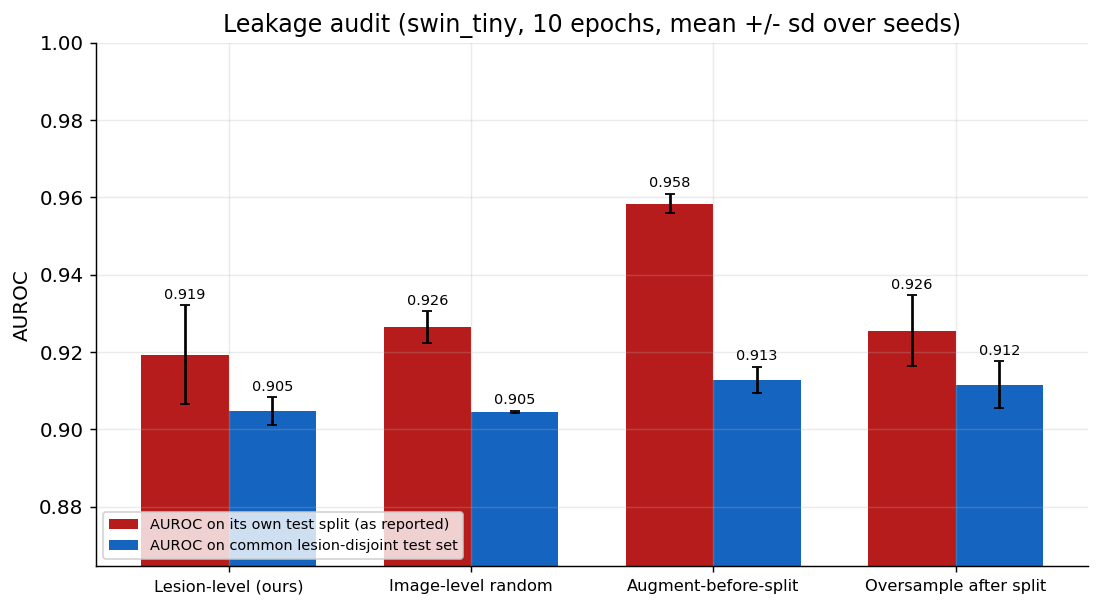


saved fig10_leakage_audit.png, leakage_audit_table.tex, leakage_audit_summary.csv


In [31]:
ORDER = ["A_lesion_level", "B_image_level", "C_augment_before", "D_oversample_after"]
NAMES = {"A_lesion_level": "Lesion-level (ours)", "B_image_level": "Image-level random",
         "C_augment_before": "Augment-before-split", "D_oversample_after": "Oversample after split"}
present = [p for p in ORDER if p in set(audit_df.protocol)]

agg = (audit_df.groupby("protocol")
       .agg(n_seeds=("seed", "nunique"),
            own_auroc=("own_auroc", "mean"), own_auroc_sd=("own_auroc", "std"),
            clean_auroc=("clean_auroc", "mean"), clean_auroc_sd=("clean_auroc", "std"),
            own_acc=("own_acc", "mean"), own_acc_sd=("own_acc", "std"),
            clean_acc=("clean_acc", "mean"), clean_acc_sd=("clean_acc", "std"),
            leak_lesion=("leak_lesion_pct", "mean"), leak_image=("leak_image_pct", "mean"))
       .reindex(present).reset_index())
for col in ["own_auroc_sd", "clean_auroc_sd", "own_acc_sd", "clean_acc_sd"]:
    agg[col] = agg[col].fillna(0.0)
agg["gap_auroc"] = agg.own_auroc - agg.clean_auroc
agg["gap_acc"] = agg.own_acc - agg.clean_acc

A = audit_df[audit_df.protocol == "A_lesion_level"].set_index("seed")
net = {}
for p in present:
    d = audit_df[audit_df.protocol == p].set_index("seed")
    s = sorted(set(A.index) & set(d.index))
    na = ((d.loc[s, "own_auroc"] - d.loc[s, "clean_auroc"]) - (A.loc[s, "own_auroc"] - A.loc[s, "clean_auroc"])).values
    nc = ((d.loc[s, "own_acc"] - d.loc[s, "clean_acc"]) - (A.loc[s, "own_acc"] - A.loc[s, "clean_acc"])).values * 100
    net[p] = (na, nc)

print(f"{'Protocol':<24}{'seeds':>6}{'reported AUROC':>17}{'clean AUROC':>15}{'net AUROC vs A':>17}{'net acc vs A':>15}")
for _, r in agg.iterrows():
    na, nc = net[r.protocol]
    sd = lambda x: f"{np.std(x, ddof=1):.4f}" if len(x) > 1 else "n/a"
    print(f"{NAMES[r.protocol]:<24}{int(r.n_seeds):>6}"
          f"{r.own_auroc:>10.4f}+/-{r.own_auroc_sd:.3f}"
          f"{r.clean_auroc:>9.4f}+/-{r.clean_auroc_sd:.3f}"
          f"{na.mean():>+11.4f}+/-{sd(na)}"
          f"{nc.mean():>+9.2f}+/-{(np.std(nc, ddof=1) if len(nc) > 1 else 0):.2f}")

if "D_oversample_after" in present and "C_augment_before" in present:
    C = audit_df[audit_df.protocol == "C_augment_before"].set_index("seed")
    D = audit_df[audit_df.protocol == "D_oversample_after"].set_index("seed")
    s = sorted(set(C.index) & set(D.index))
    dA = (C.loc[s, "own_auroc"] - D.loc[s, "own_auroc"]).values
    dc = (C.loc[s, "own_acc"] - D.loc[s, "own_acc"]).values * 100
    dcl = (C.loc[s, "clean_auroc"] - D.loc[s, "clean_auroc"]).values
    print(f"\nC vs D over {len(s)} seed(s) - matched class balance, near-equal training size:")
    print(f"  reported AUROC  {dA.mean():+.4f}   reported accuracy {dc.mean():+.2f} pts")
    print(f"  clean AUROC     {dcl.mean():+.4f}   (near zero = the extra reported score is leakage)")

def boot_auc_diff(pa, pb, y, n=1000, seed=SEED):
    r = np.random.RandomState(seed); out = []
    for _ in range(n):
        i = r.randint(0, len(y), len(y))
        if 0 < y[i].sum() < len(i):
            out.append(roc_auc_score(y[i], pb[i]) - roc_auc_score(y[i], pa[i]))
    return np.mean(out), np.percentile(out, 2.5), np.percentile(out, 97.5)

print("\nClean-test AUROC vs Protocol A (paired bootstrap, per seed):")
for p in present[1:]:
    for sd_ in sorted(audit_df[audit_df.protocol == p].seed.unique()):
        ka, kb = f"A_lesion_level_s{sd_}", f"{p}_s{sd_}"
        if ka in audit_probs_store and kb in audit_probs_store:
            a, b = audit_probs_store[ka], audit_probs_store[kb]
            m, lo, hi = boot_auc_diff(a["clean_probs"], b["clean_probs"], a["clean_labels"])
            print(f"  {NAMES[p]:<24} seed {sd_:<5} {m:+.4f} [{lo:+.4f}, {hi:+.4f}]")

fig, ax = plt.subplots(figsize=(8.6, 4.8))
x = np.arange(len(agg)); w = 0.36
b1 = ax.bar(x - w/2, agg.own_auroc, w, yerr=agg.own_auroc_sd.fillna(0), capsize=3,
            color="#B71C1C", label="AUROC on its own test split (as reported)")
b2 = ax.bar(x + w/2, agg.clean_auroc, w, yerr=agg.clean_auroc_sd.fillna(0), capsize=3,
            color="#1565C0", label="AUROC on common lesion-disjoint test set")
ax.bar_label(b1, fmt="%.3f", padding=2, fontsize=8); ax.bar_label(b2, fmt="%.3f", padding=2, fontsize=8)
ax.set_xticks(x); ax.set_xticklabels([NAMES[p] for p in agg.protocol], fontsize=9)
ax.set_ylim(min(agg.clean_auroc) - 0.04, 1.0); ax.set_ylabel("AUROC")
ax.set_title(f"Leakage audit ({AUDIT_BACKBONE}, {AUDIT_EPOCHS} epochs, mean +/- sd over seeds)")
ax.legend(fontsize=8, loc="lower left"); fig.tight_layout()
fig.savefig(FIG_DIR + "fig10_leakage_audit.png", bbox_inches="tight"); plt.show()

tex = ["\\begin{tabular}{lcccccc}", "\\toprule",
       "Protocol & Lesion/image & Reported & Clean & Net AUROC & Reported & Clean \\\\",
       " & overlap (\\%) & AUROC & AUROC & vs A & acc. (\\%) & acc. (\\%) \\\\", "\\midrule"]
for _, r in agg.iterrows():
    na, _ = net[r.protocol]
    tex.append(f"{NAMES[r.protocol]} & {r.leak_lesion:.1f} / {r.leak_image:.1f} & "
               f"{r.own_auroc:.3f} $\\pm$ {r.own_auroc_sd:.3f} & "
               f"{r.clean_auroc:.3f} $\\pm$ {r.clean_auroc_sd:.3f} & {na.mean():+.3f} & "
               f"{r.own_acc*100:.1f} $\\pm$ {r.own_acc_sd*100:.1f} & "
               f"{r.clean_acc*100:.1f} $\\pm$ {r.clean_acc_sd*100:.1f} \\\\")
tex += ["\\bottomrule", "\\end{tabular}"]
open(AUDIT_DIR + "leakage_audit_table.tex", "w").write("\n".join(tex))
agg.to_csv(AUDIT_DIR + "leakage_audit_summary.csv", index=False)
print("\nsaved fig10_leakage_audit.png, leakage_audit_table.tex, leakage_audit_summary.csv")